# Data Visualization


## Imports & Config

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats
from collections import defaultdict
import random as _rnd


work_dir = os.getcwd()
print("work_dir:", work_dir)

# Sampling info
RAW_FS = 0.0333
TARGET_INTERVAL_SEC = 1800
FS = 1 / TARGET_INTERVAL_SEC
MINS_PER_SAMPLE = TARGET_INTERVAL_SEC / 60

# Column names
COL_NAMES_PROC = ["time", "voltage", "current", "temperature", "SoH"]
# Both GRU and CNN pipelines now produce 5 features
FEAT_COLS = ["voltage", "current", "temperature", "dV/dt", "dI/dt"]
COL_NAMES_CNN = ["voltage", "current", "temperature", "dV/dt", "dI/dt"]

# Paths
RAW_DIR = os.path.join(work_dir, "data_raw")
PROC_DIR = os.path.join(work_dir, "data_processed")
WIND_DIR = os.path.join(work_dir, "data_windowed")
NORM_DIR = os.path.join(work_dir, "data_normalized")
CNN_DIR = os.path.join(work_dir, "data_cnn")
CNN_NORM_DIR = os.path.join(work_dir, "data_cnn_normalized")
FIG_DIR = os.path.join(work_dir, "figures", "pipeline_viz")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})


def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name))
    plt.show()


def get_battery_id(fname):
    parts = fname.replace("X_", "").replace("y_", "").split("_")
    for p in parts:
        if p.startswith("P") and p[1:].isdigit():
            return p
    return parts[1] if len(parts) > 1 else parts[0]


proc_files = sorted([f for f in os.listdir(PROC_DIR) if f.endswith(".npy")])
SAMPLE_FILE = proc_files[0]
print(f"Sample file: {SAMPLE_FILE}  ({len(proc_files)} total)")


work_dir: c:\Users\Sina\Desktop\My Works\Projects\cwru-fault-detection\Battery_SoH
Sample file: processed_P001_1_S01_C10.npy  (228 total)



# Section 1: Raw / Processed Data

## 1.1 Dataset Inventory

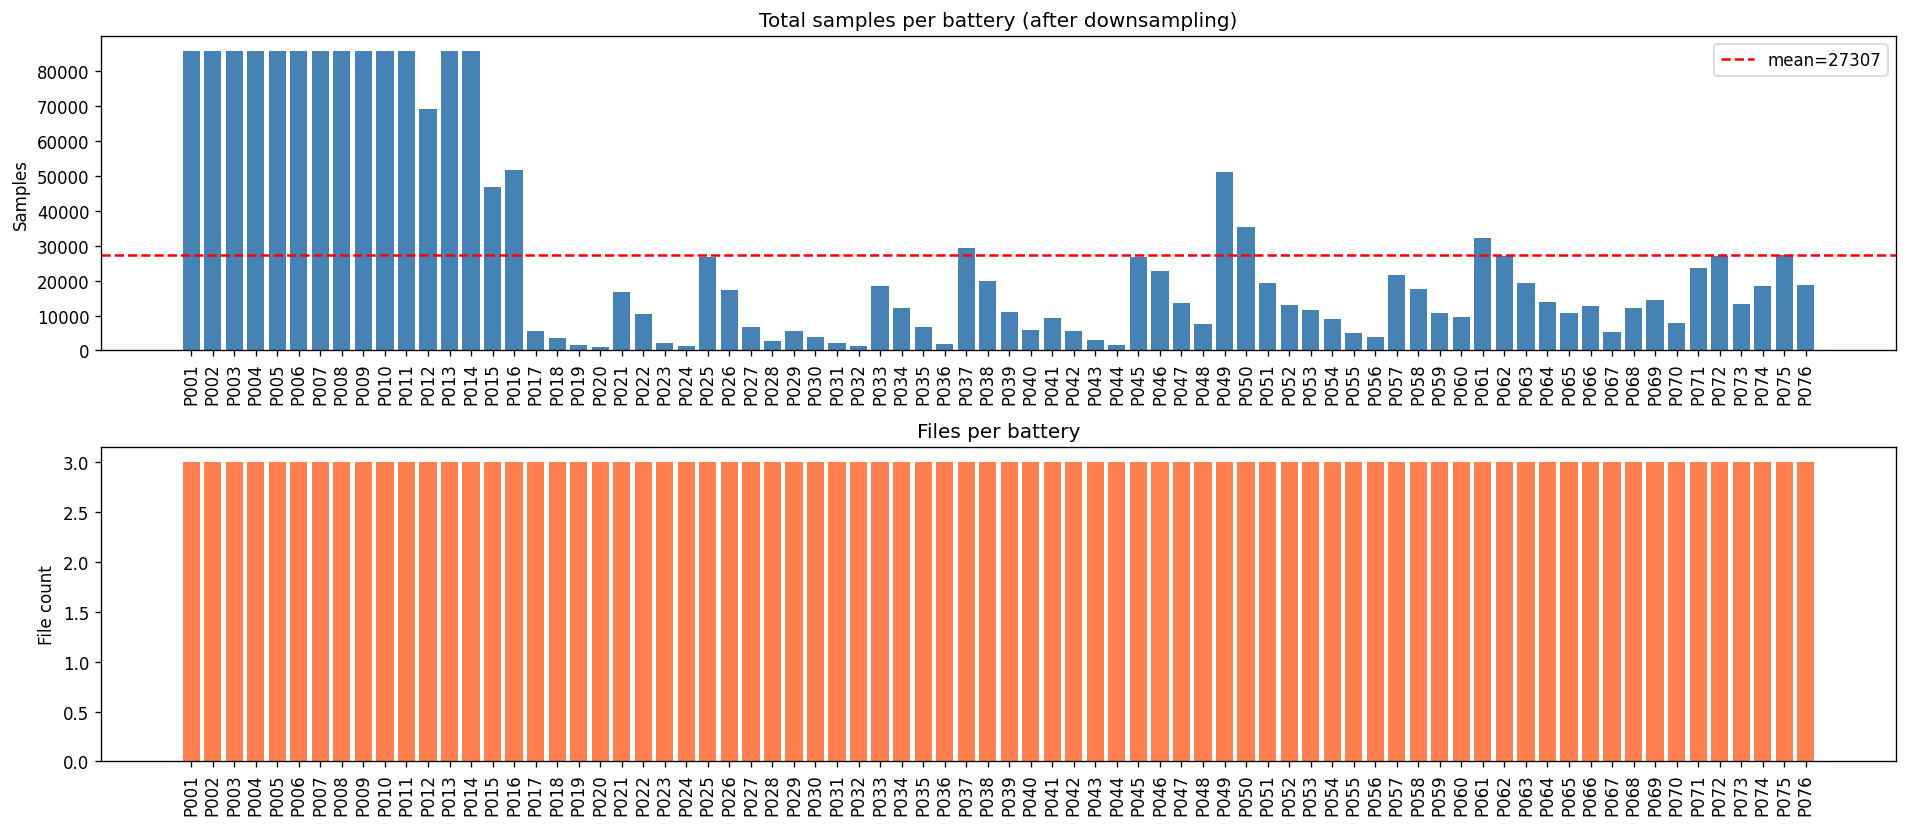

In [ ]:
battery_info = defaultdict(list)
for f in proc_files:
    bid = get_battery_id(f)
    x = np.load(os.path.join(PROC_DIR, f))
    battery_info[bid].append(x.shape[0])
bids = sorted(battery_info)
totals = [sum(battery_info[b]) for b in bids]
n_files = [len(battery_info[b]) for b in bids]

fig, axes = plt.subplots(2, 1, figsize=(16, 7))
axes[0].bar(bids, totals, color="steelblue")
axes[0].axhline(
    np.mean(totals), color="red", ls="--", label=f"mean={np.mean(totals):.0f}"
)
axes[0].set_title("Total samples per battery (after downsampling)")
axes[0].set_ylabel("Samples")
axes[0].tick_params(axis="x", rotation=90)
axes[0].legend()
axes[1].bar(bids, n_files, color="coral")
axes[1].set_title("Files per battery")
axes[1].set_ylabel("File count")
axes[1].tick_params(axis="x", rotation=90)
savefig("1_1_inventory.png")


## 1.2 Full Time-Series — Sample File

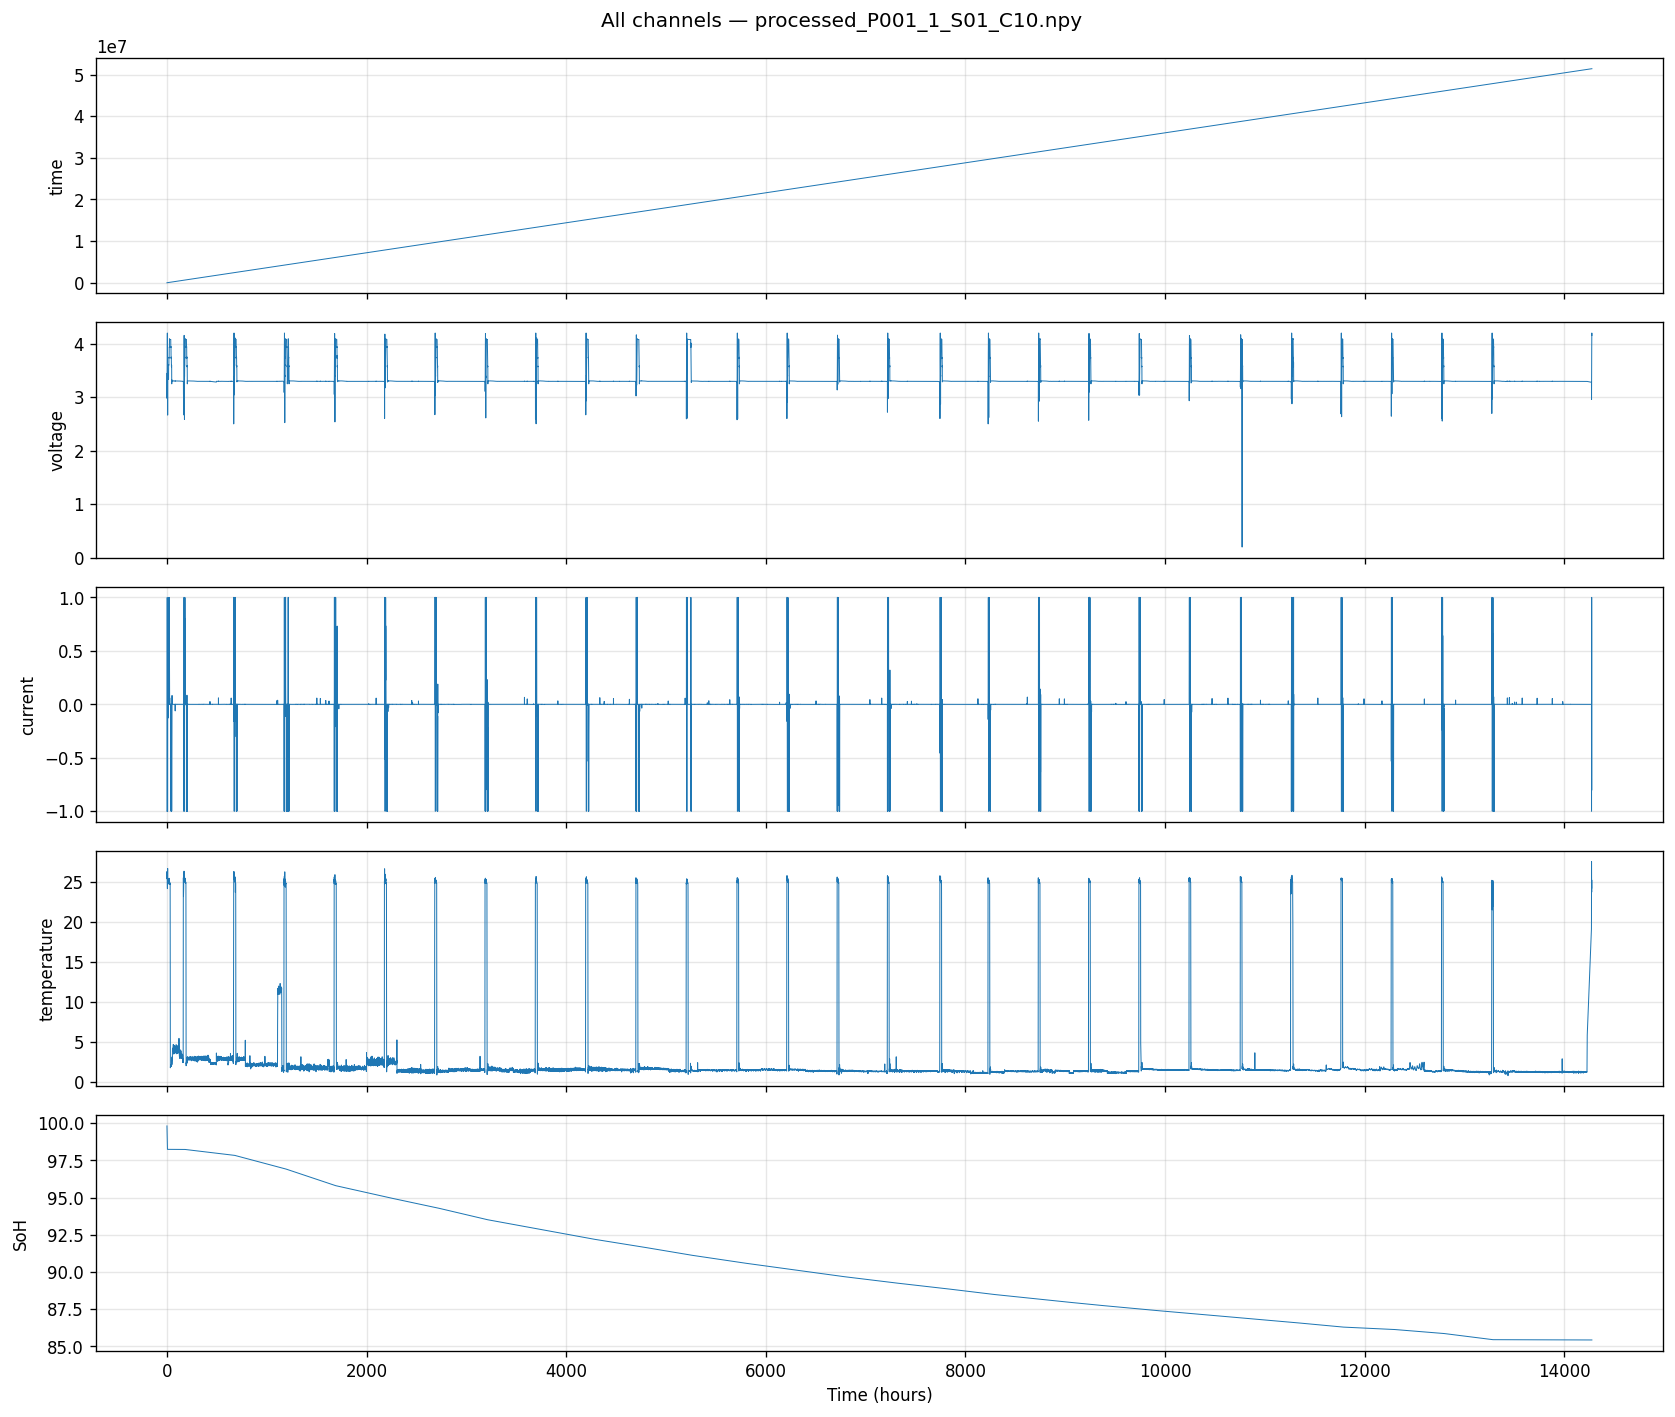

In [ ]:
x = np.load(os.path.join(PROC_DIR, SAMPLE_FILE))
t = np.arange(len(x)) * MINS_PER_SAMPLE / 60  # hours

fig, axes = plt.subplots(len(COL_NAMES_PROC), 1, figsize=(14, 12), sharex=True)
fig.suptitle(f"All channels — {SAMPLE_FILE}", fontsize=12)
for ax, col, name in zip(axes, range(len(COL_NAMES_PROC)), COL_NAMES_PROC):
    ax.plot(t, x[:, col], lw=0.6)
    ax.set_ylabel(name)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time (hours)")
savefig("1_2_full_timeseries.png")


## 1.3 Zoomed View — First 500 Samples

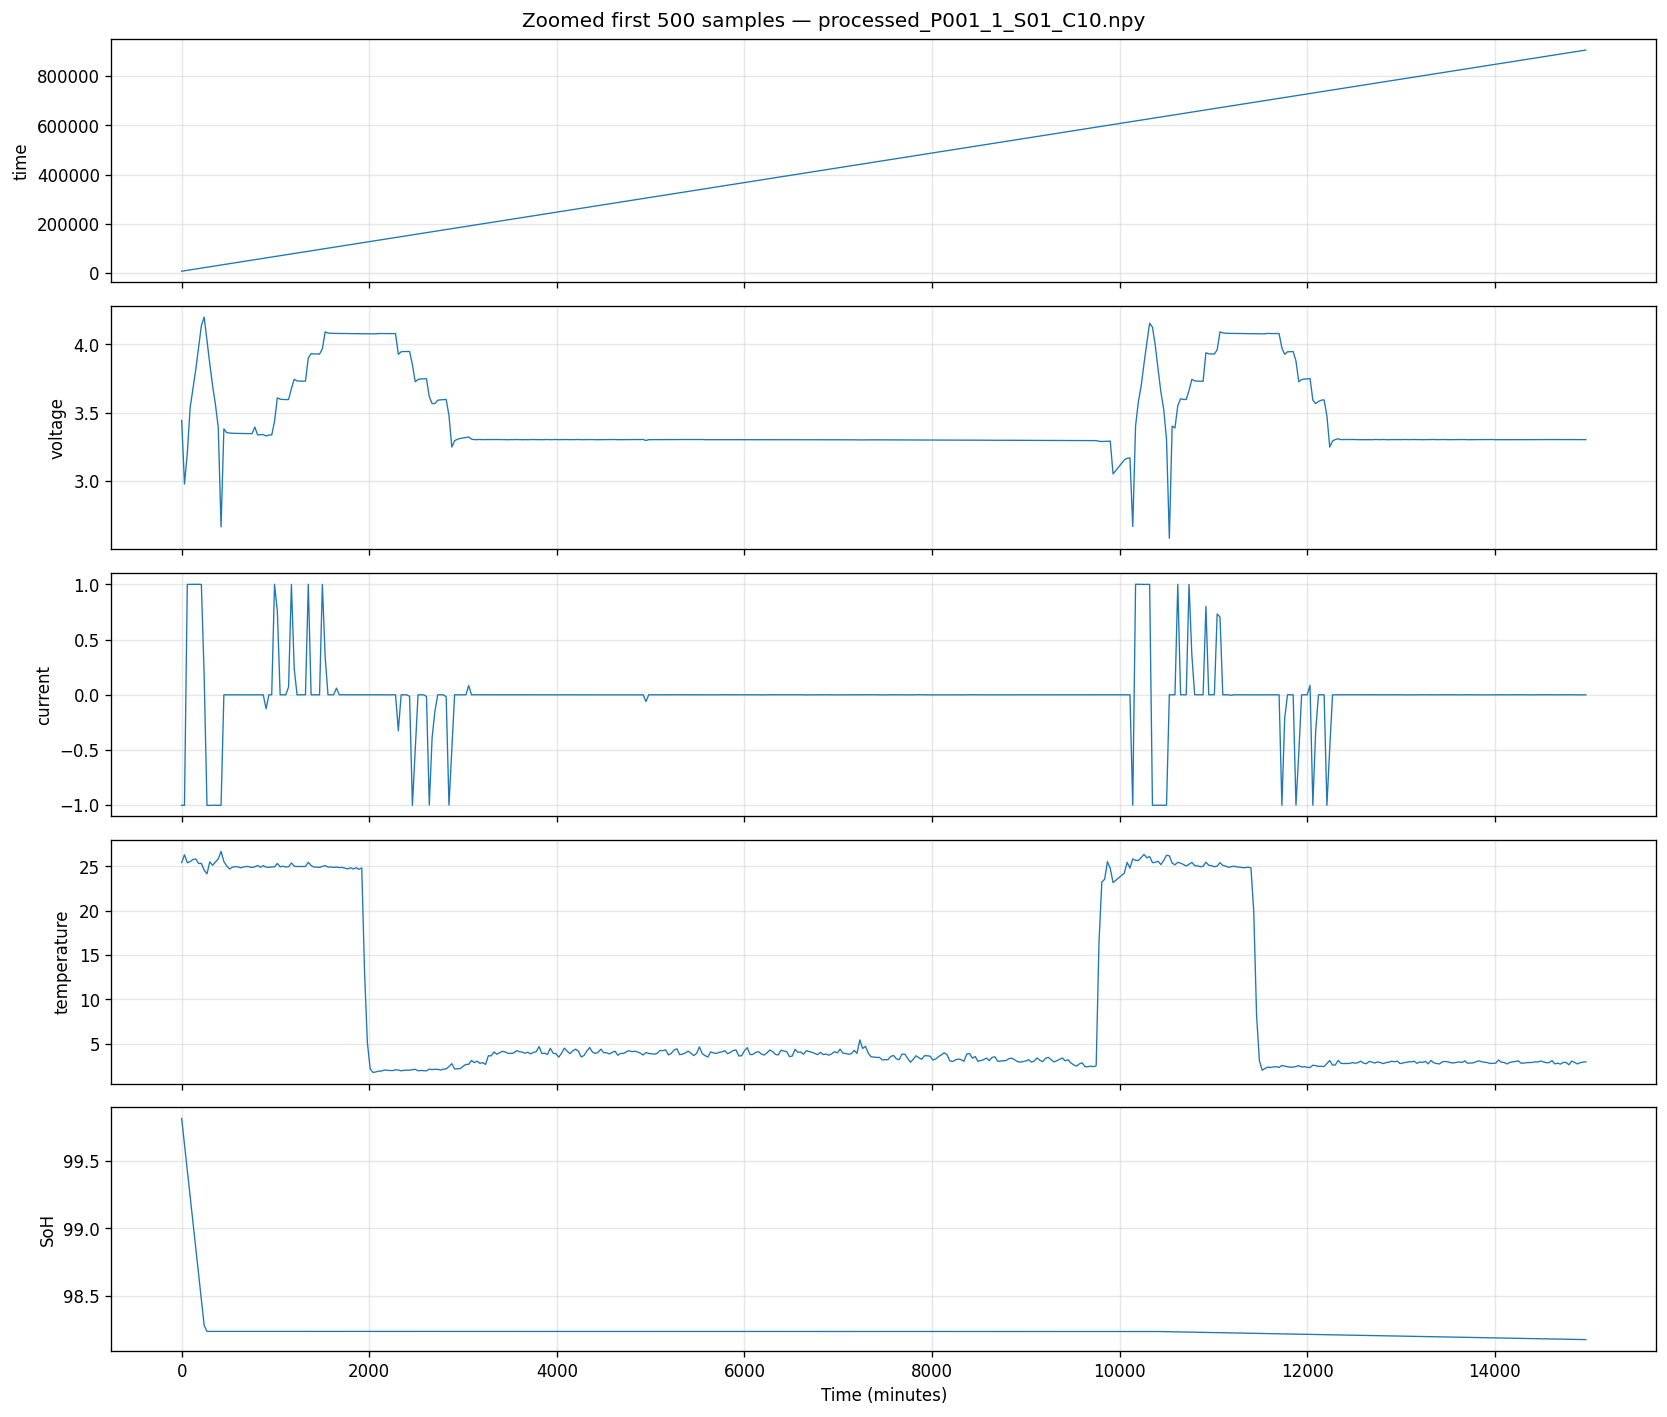

In [ ]:
zoom = min(500, len(x))
t_z = np.arange(zoom) * MINS_PER_SAMPLE
fig, axes = plt.subplots(len(COL_NAMES_PROC), 1, figsize=(14, 12), sharex=True)
fig.suptitle(f"Zoomed first {zoom} samples — {SAMPLE_FILE}")
for ax, col, name in zip(axes, range(len(COL_NAMES_PROC)), COL_NAMES_PROC):
    ax.plot(t_z, x[:zoom, col], lw=0.8)
    ax.set_ylabel(name)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time (minutes)")
savefig("1_3_zoom_timeseries.png")


## 1.4 SoH Degradation Trajectory per Battery

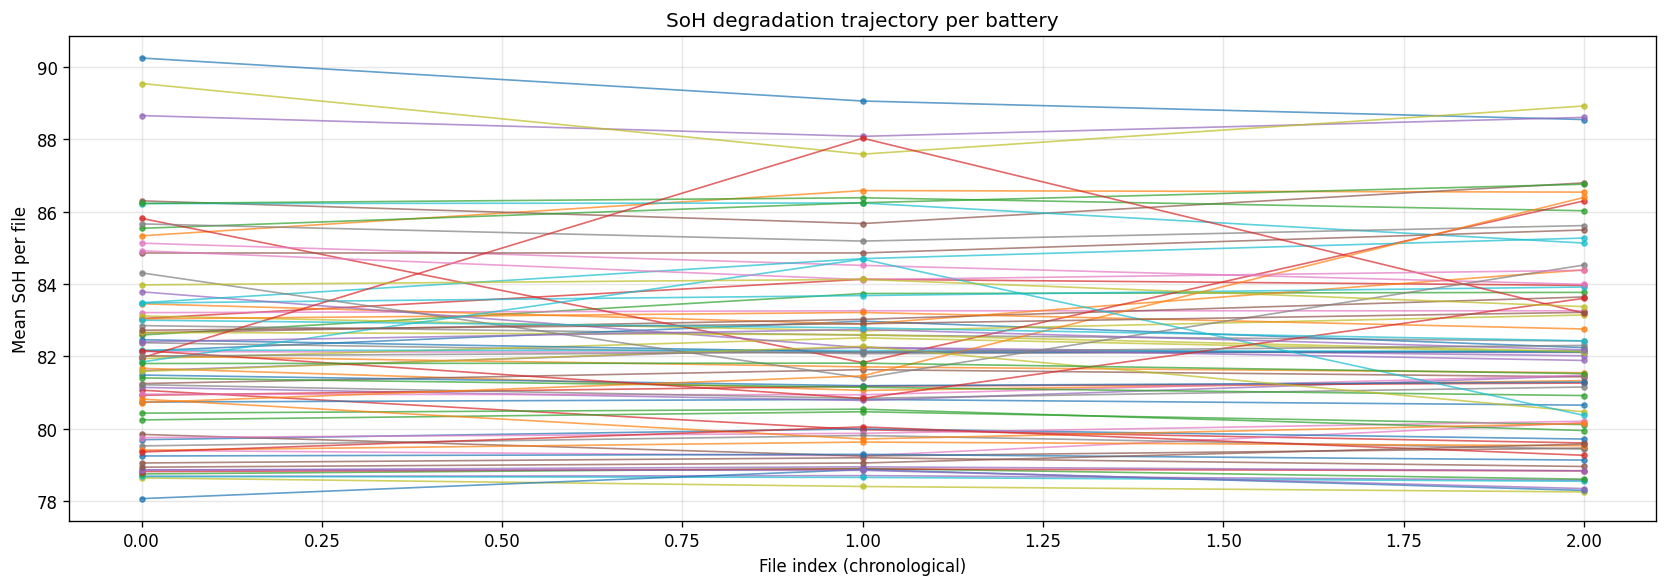

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))
for bid in bids:
    files_b = sorted([f for f in proc_files if get_battery_id(f) == bid])
    soh_vals = [np.load(os.path.join(PROC_DIR, f))[:, -1].mean() for f in files_b]
    ax.plot(range(len(soh_vals)), soh_vals, marker="o", ms=3, lw=1, alpha=0.7)
ax.set_xlabel("File index (chronological)")
ax.set_ylabel("Mean SoH per file")
ax.set_title("SoH degradation trajectory per battery")
ax.grid(alpha=0.3)
savefig("1_4_soh_trajectory.png")


## 1.5 Per-Channel Distribution

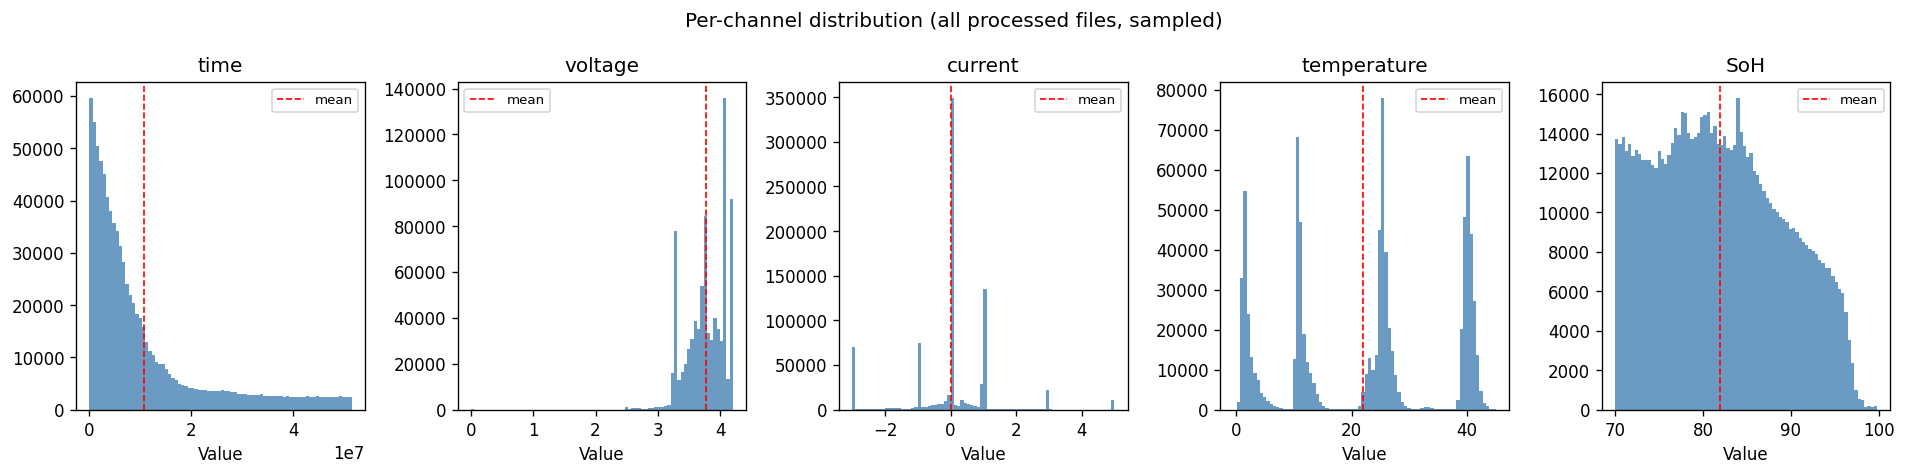

In [ ]:
sample_rows = 5000
all_data = []
for f in proc_files:
    d = np.load(os.path.join(PROC_DIR, f))
    idx = np.random.choice(len(d), min(sample_rows, len(d)), replace=False)
    all_data.append(d[idx])
all_data = np.concatenate(all_data)

fig, axes = plt.subplots(1, len(COL_NAMES_PROC), figsize=(16, 4))
for ax, i, name in zip(axes, range(len(COL_NAMES_PROC)), COL_NAMES_PROC):
    ax.hist(all_data[:, i], bins=80, color="steelblue", edgecolor="none", alpha=0.8)
    ax.axvline(all_data[:, i].mean(), color="red", ls="--", lw=1, label="mean")
    ax.set_title(name)
    ax.set_xlabel("Value")
    ax.legend(fontsize=8)
fig.suptitle("Per-channel distribution (all processed files, sampled)")
savefig("1_5_channel_distributions.png")


## 1.6 Scatter Matrix

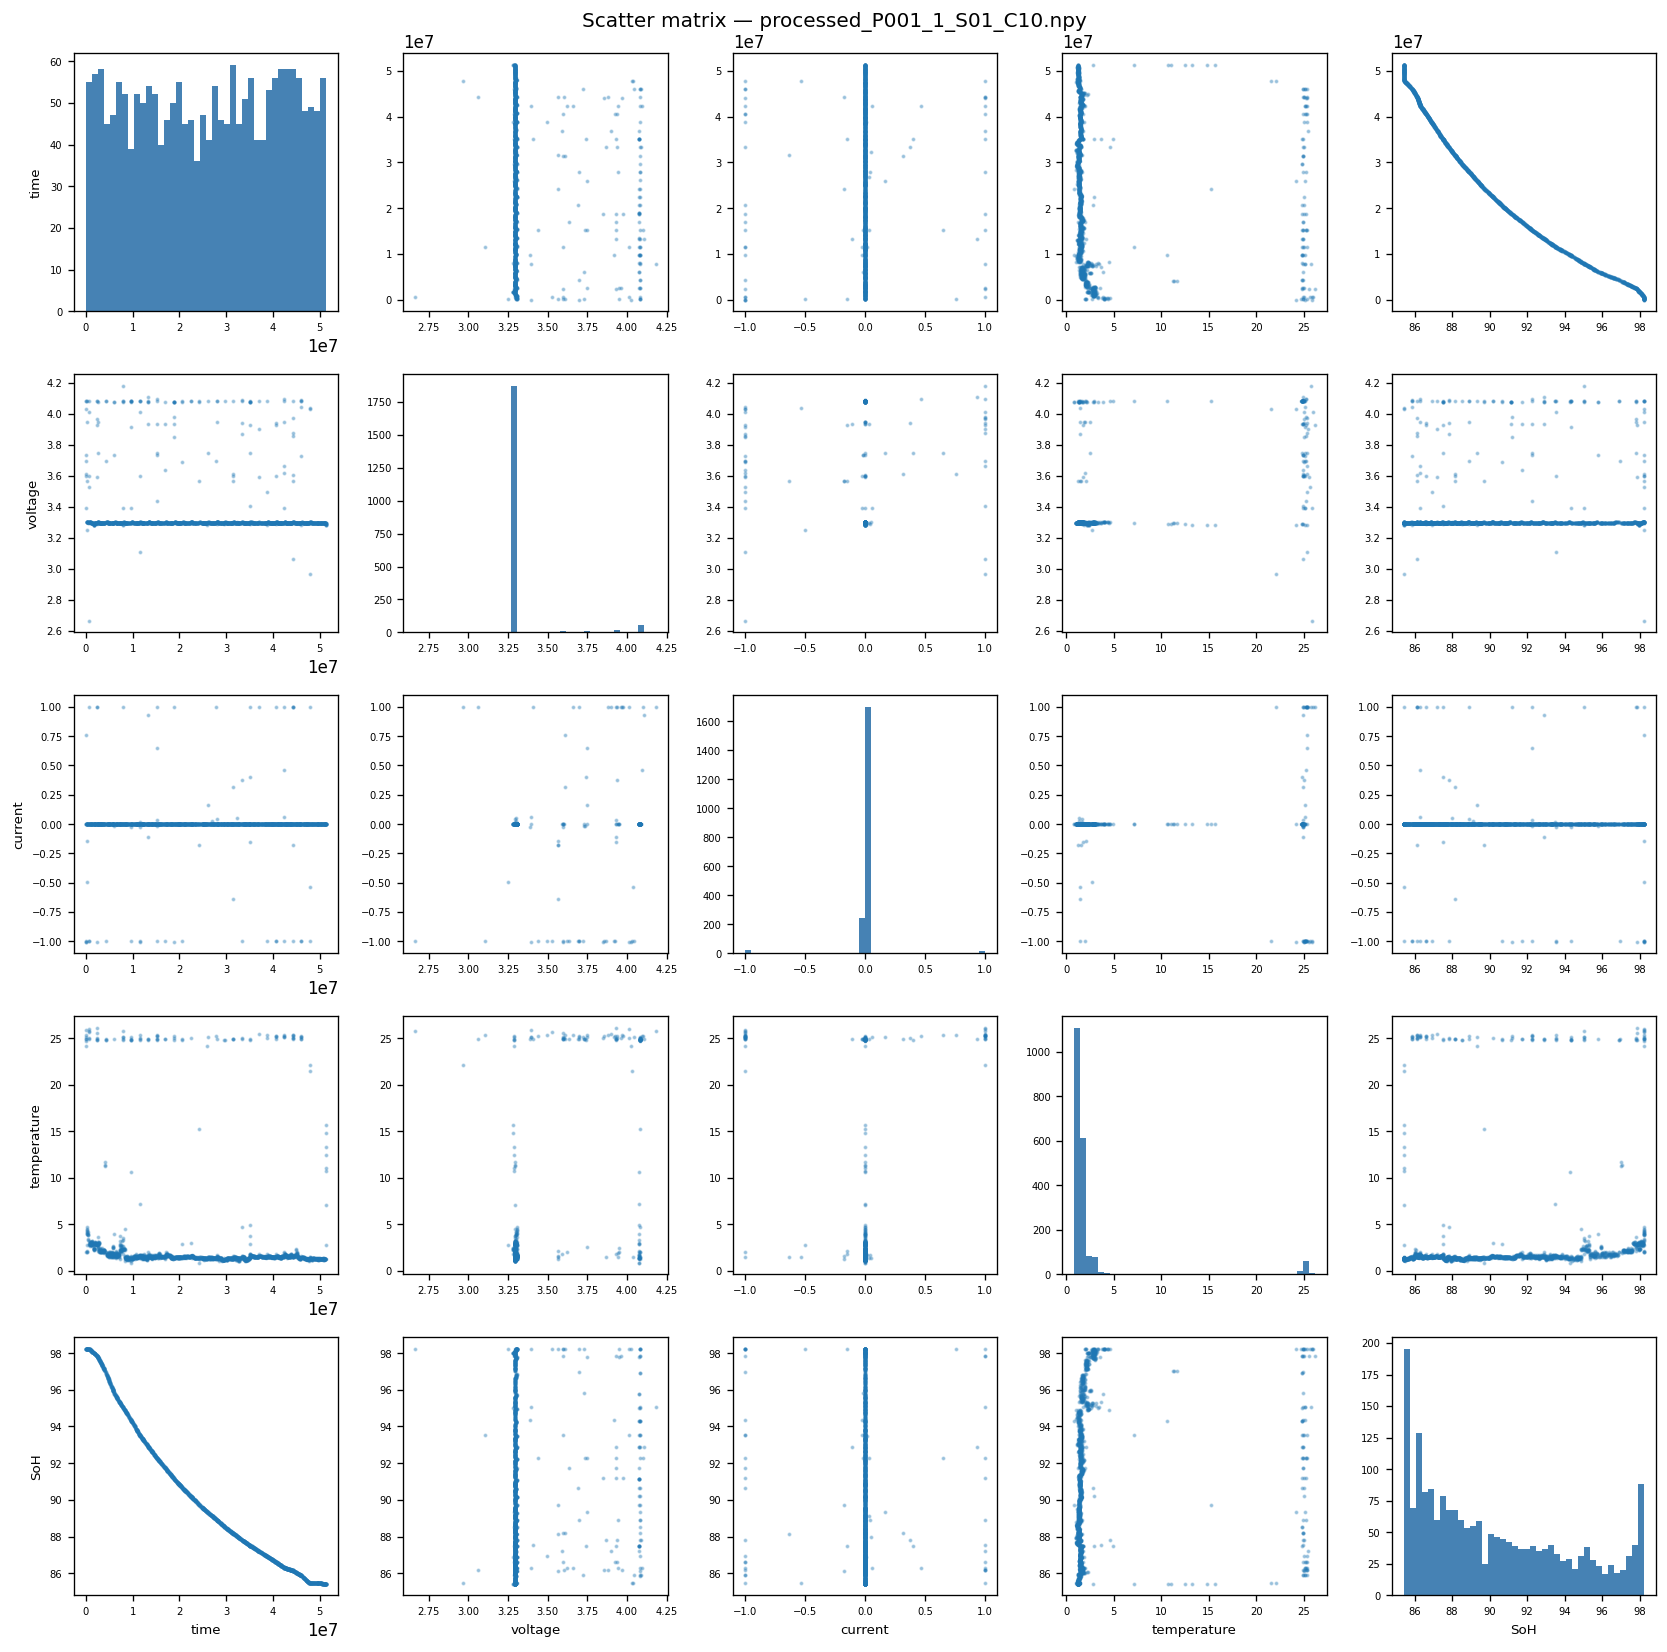

In [ ]:
x = np.load(os.path.join(PROC_DIR, SAMPLE_FILE))
xs = x[_rnd.sample(range(len(x)), min(2000, len(x)))]
n = len(COL_NAMES_PROC)
fig, axes = plt.subplots(n, n, figsize=(14, 14))
for i in range(n):
    for j in range(n):
        ax = axes[i][j]
        if i == j:
            ax.hist(xs[:, i], bins=40, color="steelblue", edgecolor="none")
        else:
            ax.scatter(xs[:, j], xs[:, i], s=2, alpha=0.3)
        if j == 0:
            ax.set_ylabel(COL_NAMES_PROC[i], fontsize=8)
        if i == n - 1:
            ax.set_xlabel(COL_NAMES_PROC[j], fontsize=8)
        ax.tick_params(labelsize=6)
fig.suptitle(f"Scatter matrix — {SAMPLE_FILE}")
savefig("1_6_scatter_matrix.png")


## 1.7 Correlation Heatmap

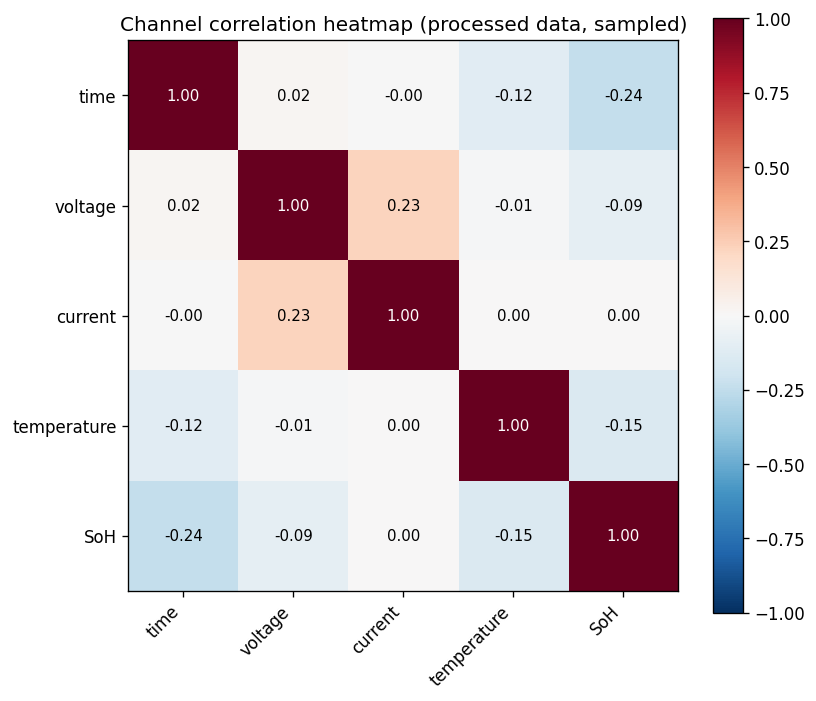

In [ ]:
corr = np.corrcoef(all_data.T)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(COL_NAMES_PROC)))
ax.set_xticklabels(COL_NAMES_PROC, rotation=45, ha="right")
ax.set_yticks(range(len(COL_NAMES_PROC)))
ax.set_yticklabels(COL_NAMES_PROC)
for i in range(len(COL_NAMES_PROC)):
    for j in range(len(COL_NAMES_PROC)):
        ax.text(
            j,
            i,
            f"{corr[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if abs(corr[i, j]) > 0.6 else "black",
        )
ax.set_title("Channel correlation heatmap (processed data, sampled)")
savefig("1_7_correlation_heatmap.png")


## 1.8 Per-Battery Box-Plot

C:\Users\Sina\AppData\Local\Temp\ipykernel_20392\3797822277.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_bat, labels=bids, vert=True)
C:\Users\Sina\AppData\Local\Temp\ipykernel_20392\3797822277.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_bat, labels=bids, vert=True)
C:\Users\Sina\AppData\Local\Temp\ipykernel_20392\3797822277.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_bat, labels=bids, vert=True)
C:\Users\Sina\AppData\Local\Temp\ipykernel_20392\3797822277.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been r

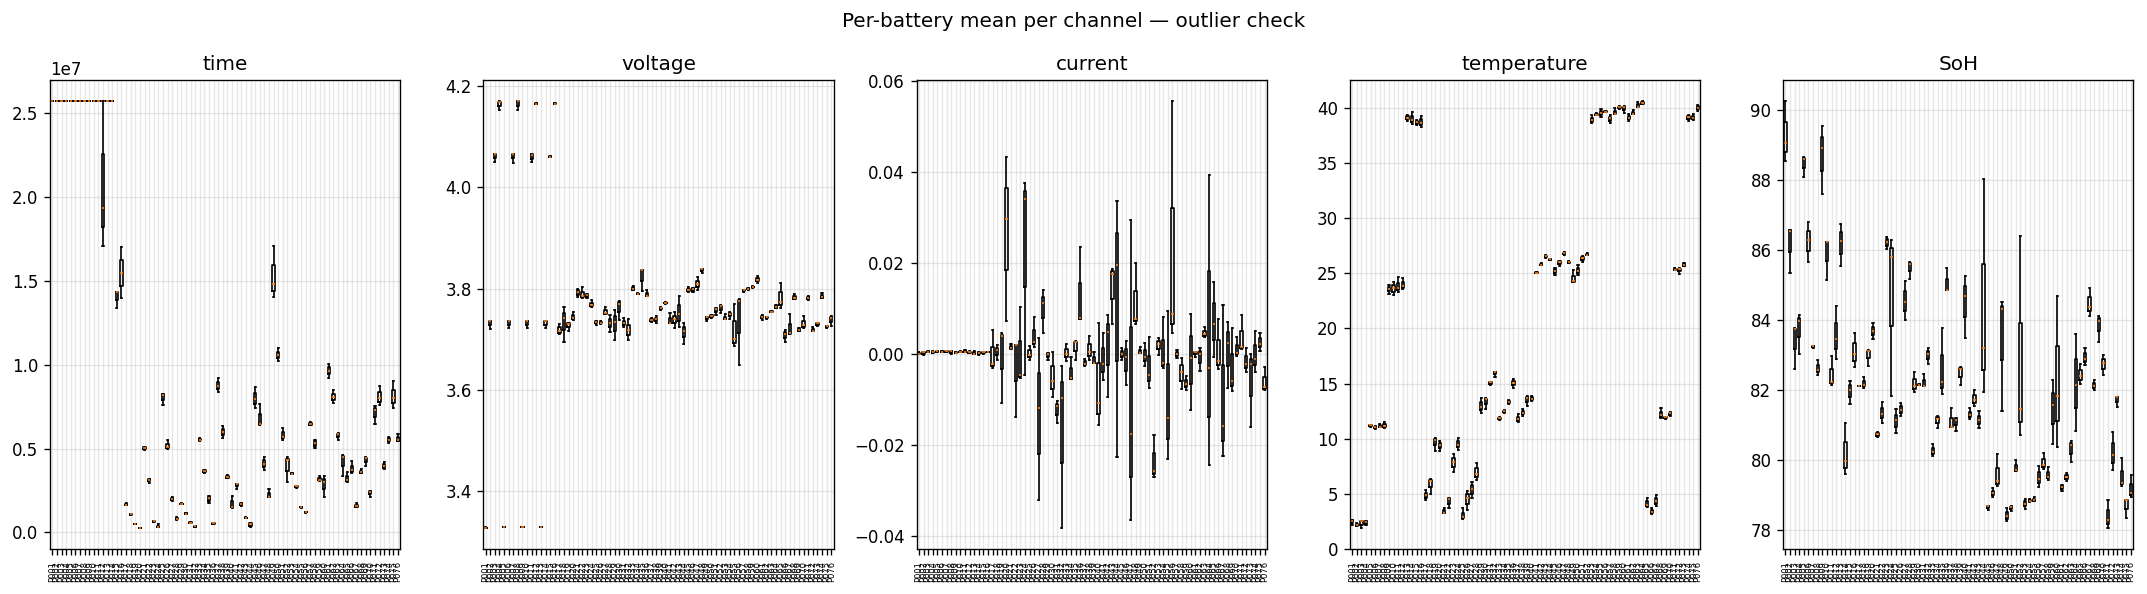

In [ ]:
fig, axes = plt.subplots(1, len(COL_NAMES_PROC), figsize=(18, 5))
for ch, (ax, name) in enumerate(zip(axes, COL_NAMES_PROC)):
    data_per_bat = [
        [
            np.load(os.path.join(PROC_DIR, f))[:, ch].mean()
            for f in proc_files
            if get_battery_id(f) == b
        ]
        for b in bids
    ]
    ax.boxplot(data_per_bat, labels=bids, vert=True)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=90, labelsize=5)
    ax.grid(alpha=0.3)
fig.suptitle("Per-battery mean per channel — outlier check")
savefig("1_8_per_battery_boxplot.png")



# Section 2 — Frequency Domain

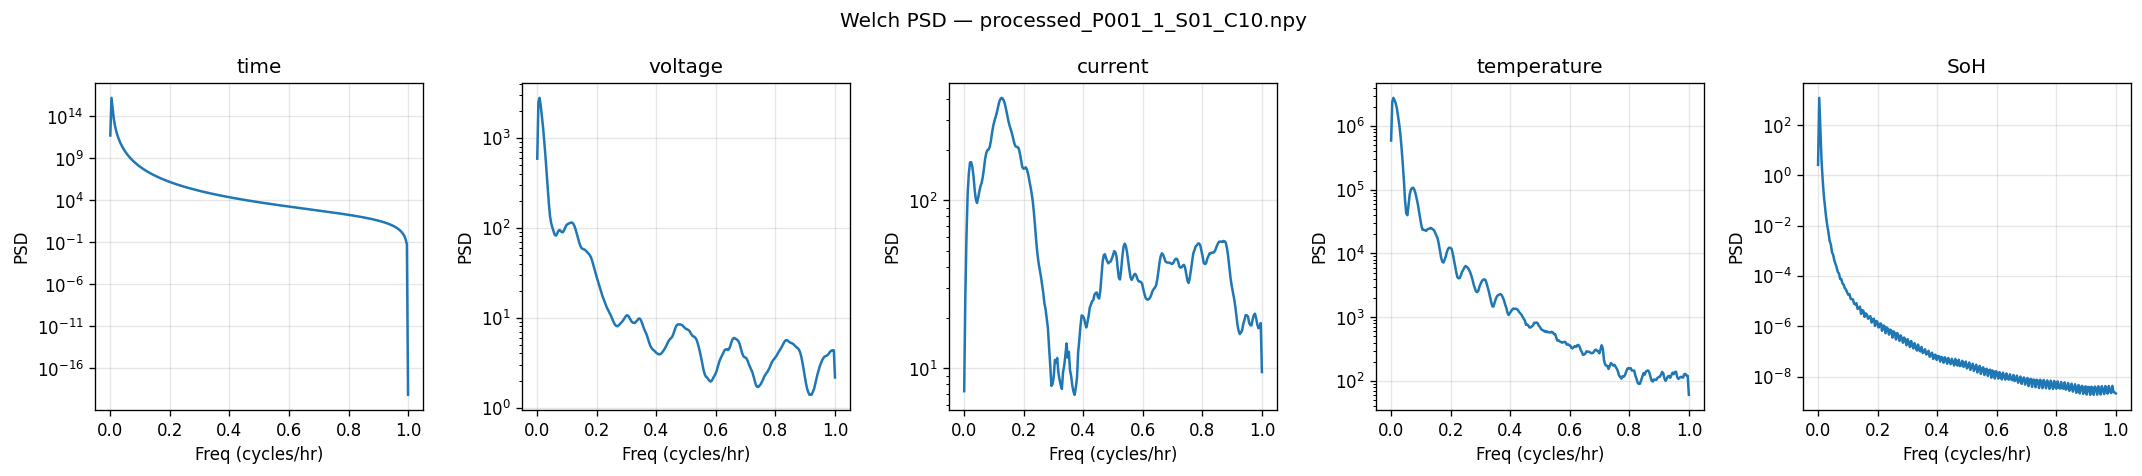

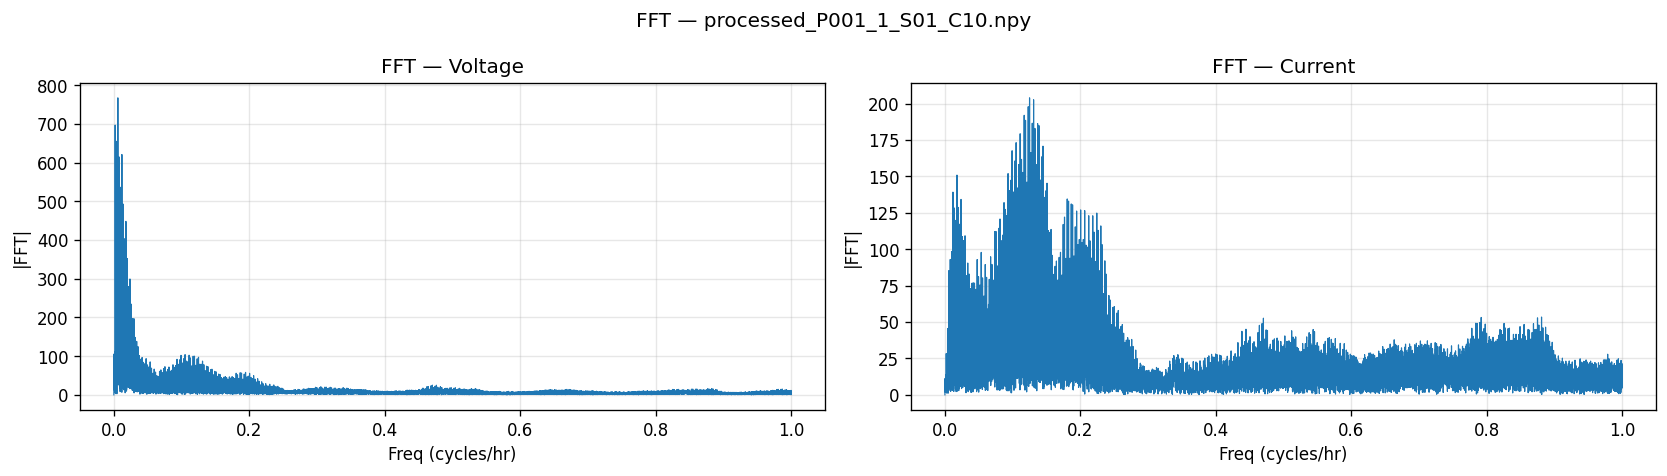

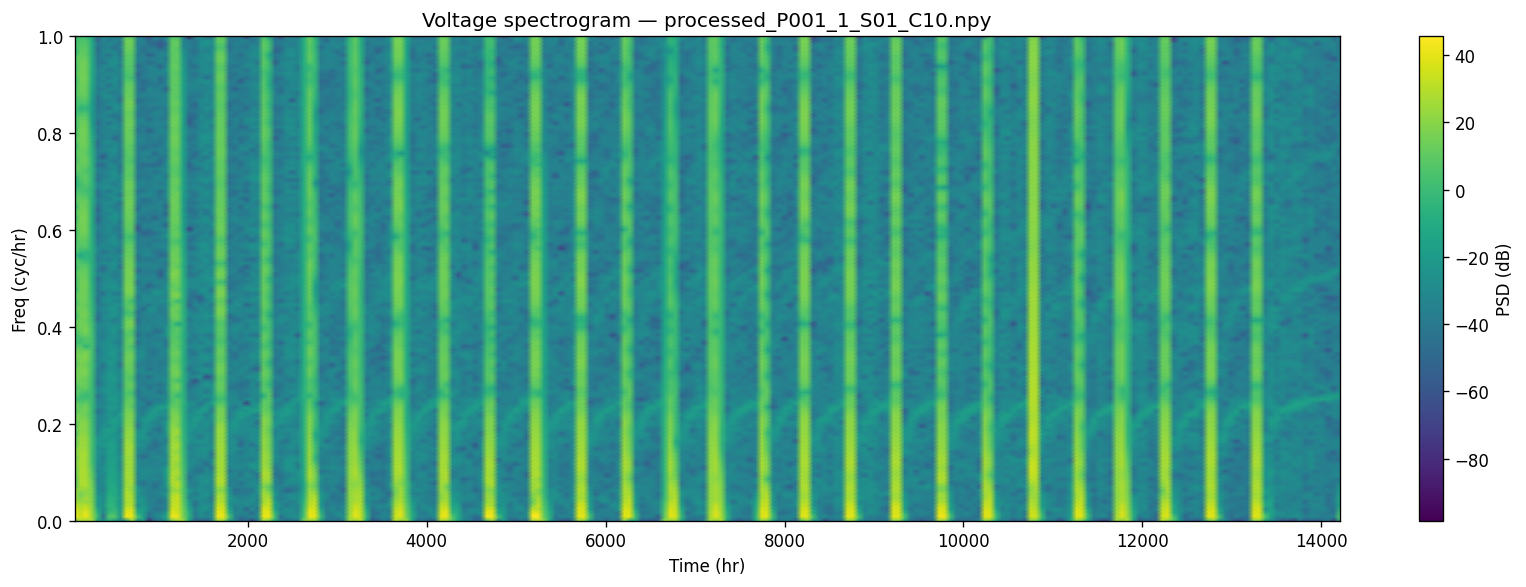

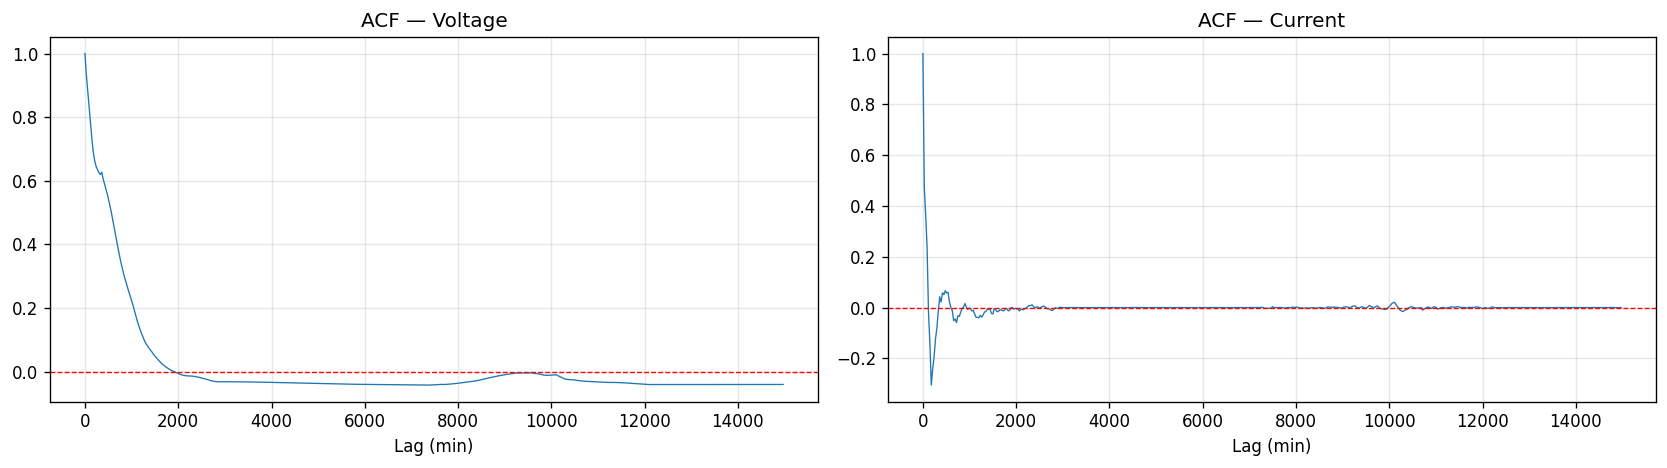

In [ ]:
x = np.load(os.path.join(PROC_DIR, SAMPLE_FILE))

# 2.1 Welch PSD
fig, axes = plt.subplots(1, len(COL_NAMES_PROC), figsize=(18, 4))
for ax, i, name in zip(axes, range(len(COL_NAMES_PROC)), COL_NAMES_PROC):
    f_p, pxx = signal.welch(x[:, i], fs=FS, nperseg=min(512, len(x) // 4))
    ax.semilogy(f_p * 3600, pxx)
    ax.set_title(name)
    ax.set_xlabel("Freq (cycles/hr)")
    ax.set_ylabel("PSD")
    ax.grid(alpha=0.3)
fig.suptitle(f"Welch PSD — {SAMPLE_FILE}")
savefig("2_1_psd_welch.png")

# 2.2 FFT
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, ci, name in zip(axes, [1, 2], ["Voltage", "Current"]):
    sig = x[:, ci] - x[:, ci].mean()
    fft_v = np.abs(np.fft.rfft(sig))
    freqs = np.fft.rfftfreq(len(sig), d=1 / FS) * 3600
    ax.plot(freqs, fft_v, lw=0.7)
    ax.set_title(f"FFT — {name}")
    ax.set_xlabel("Freq (cycles/hr)")
    ax.set_ylabel("|FFT|")
    ax.grid(alpha=0.3)
fig.suptitle(f"FFT — {SAMPLE_FILE}")
savefig("2_2_fft_magnitude.png")

# 2.3 Spectrogram voltage
nperseg = min(256, len(x) // 8)
f_s, t_s, Sxx = signal.spectrogram(
    x[:, 1], fs=FS, nperseg=nperseg, noverlap=nperseg // 2
)
fig, ax = plt.subplots(figsize=(14, 5))
pcm = ax.pcolormesh(
    t_s / 3600,
    f_s * 3600,
    10 * np.log10(Sxx + 1e-12),
    shading="gouraud",
    cmap="viridis",
)
plt.colorbar(pcm, ax=ax, label="PSD (dB)")
ax.set_xlabel("Time (hr)")
ax.set_ylabel("Freq (cyc/hr)")
ax.set_title(f"Voltage spectrogram — {SAMPLE_FILE}")
savefig("2_3_spectrogram_voltage.png")

# 2.4 Autocorrelation
max_lag = min(500, len(x) // 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, ci, name in zip(axes, [1, 2], ["Voltage", "Current"]):
    sig = x[:, ci] - x[:, ci].mean()
    acf = np.correlate(sig, sig, mode="full")
    acf = acf[len(acf) // 2 :]
    acf /= acf[0]
    lags = np.arange(max_lag) * MINS_PER_SAMPLE
    ax.plot(lags, acf[:max_lag], lw=0.8)
    ax.axhline(0, color="red", ls="--", lw=0.8)
    ax.set_title(f"ACF — {name}")
    ax.set_xlabel("Lag (min)")
    ax.grid(alpha=0.3)
savefig("2_4_autocorrelation.png")



# Section 3 — Windowed Data (GRU/XGB)


Total windows: 12,683  SoH: [70.000,97.916]


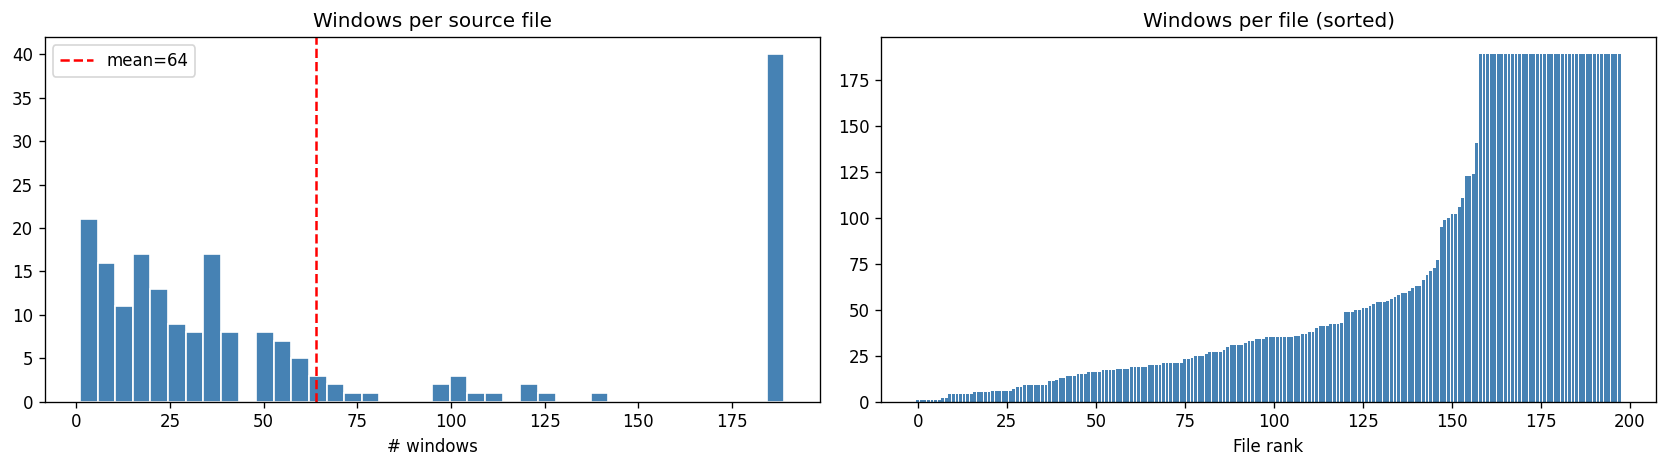

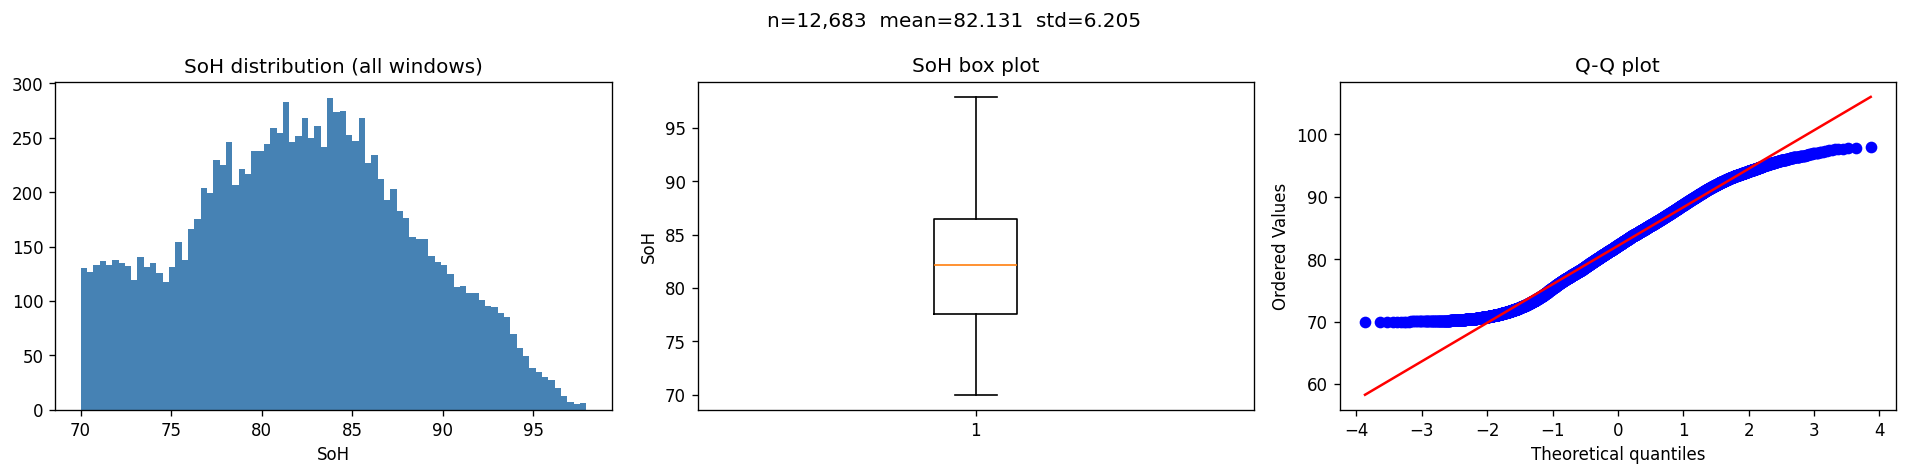

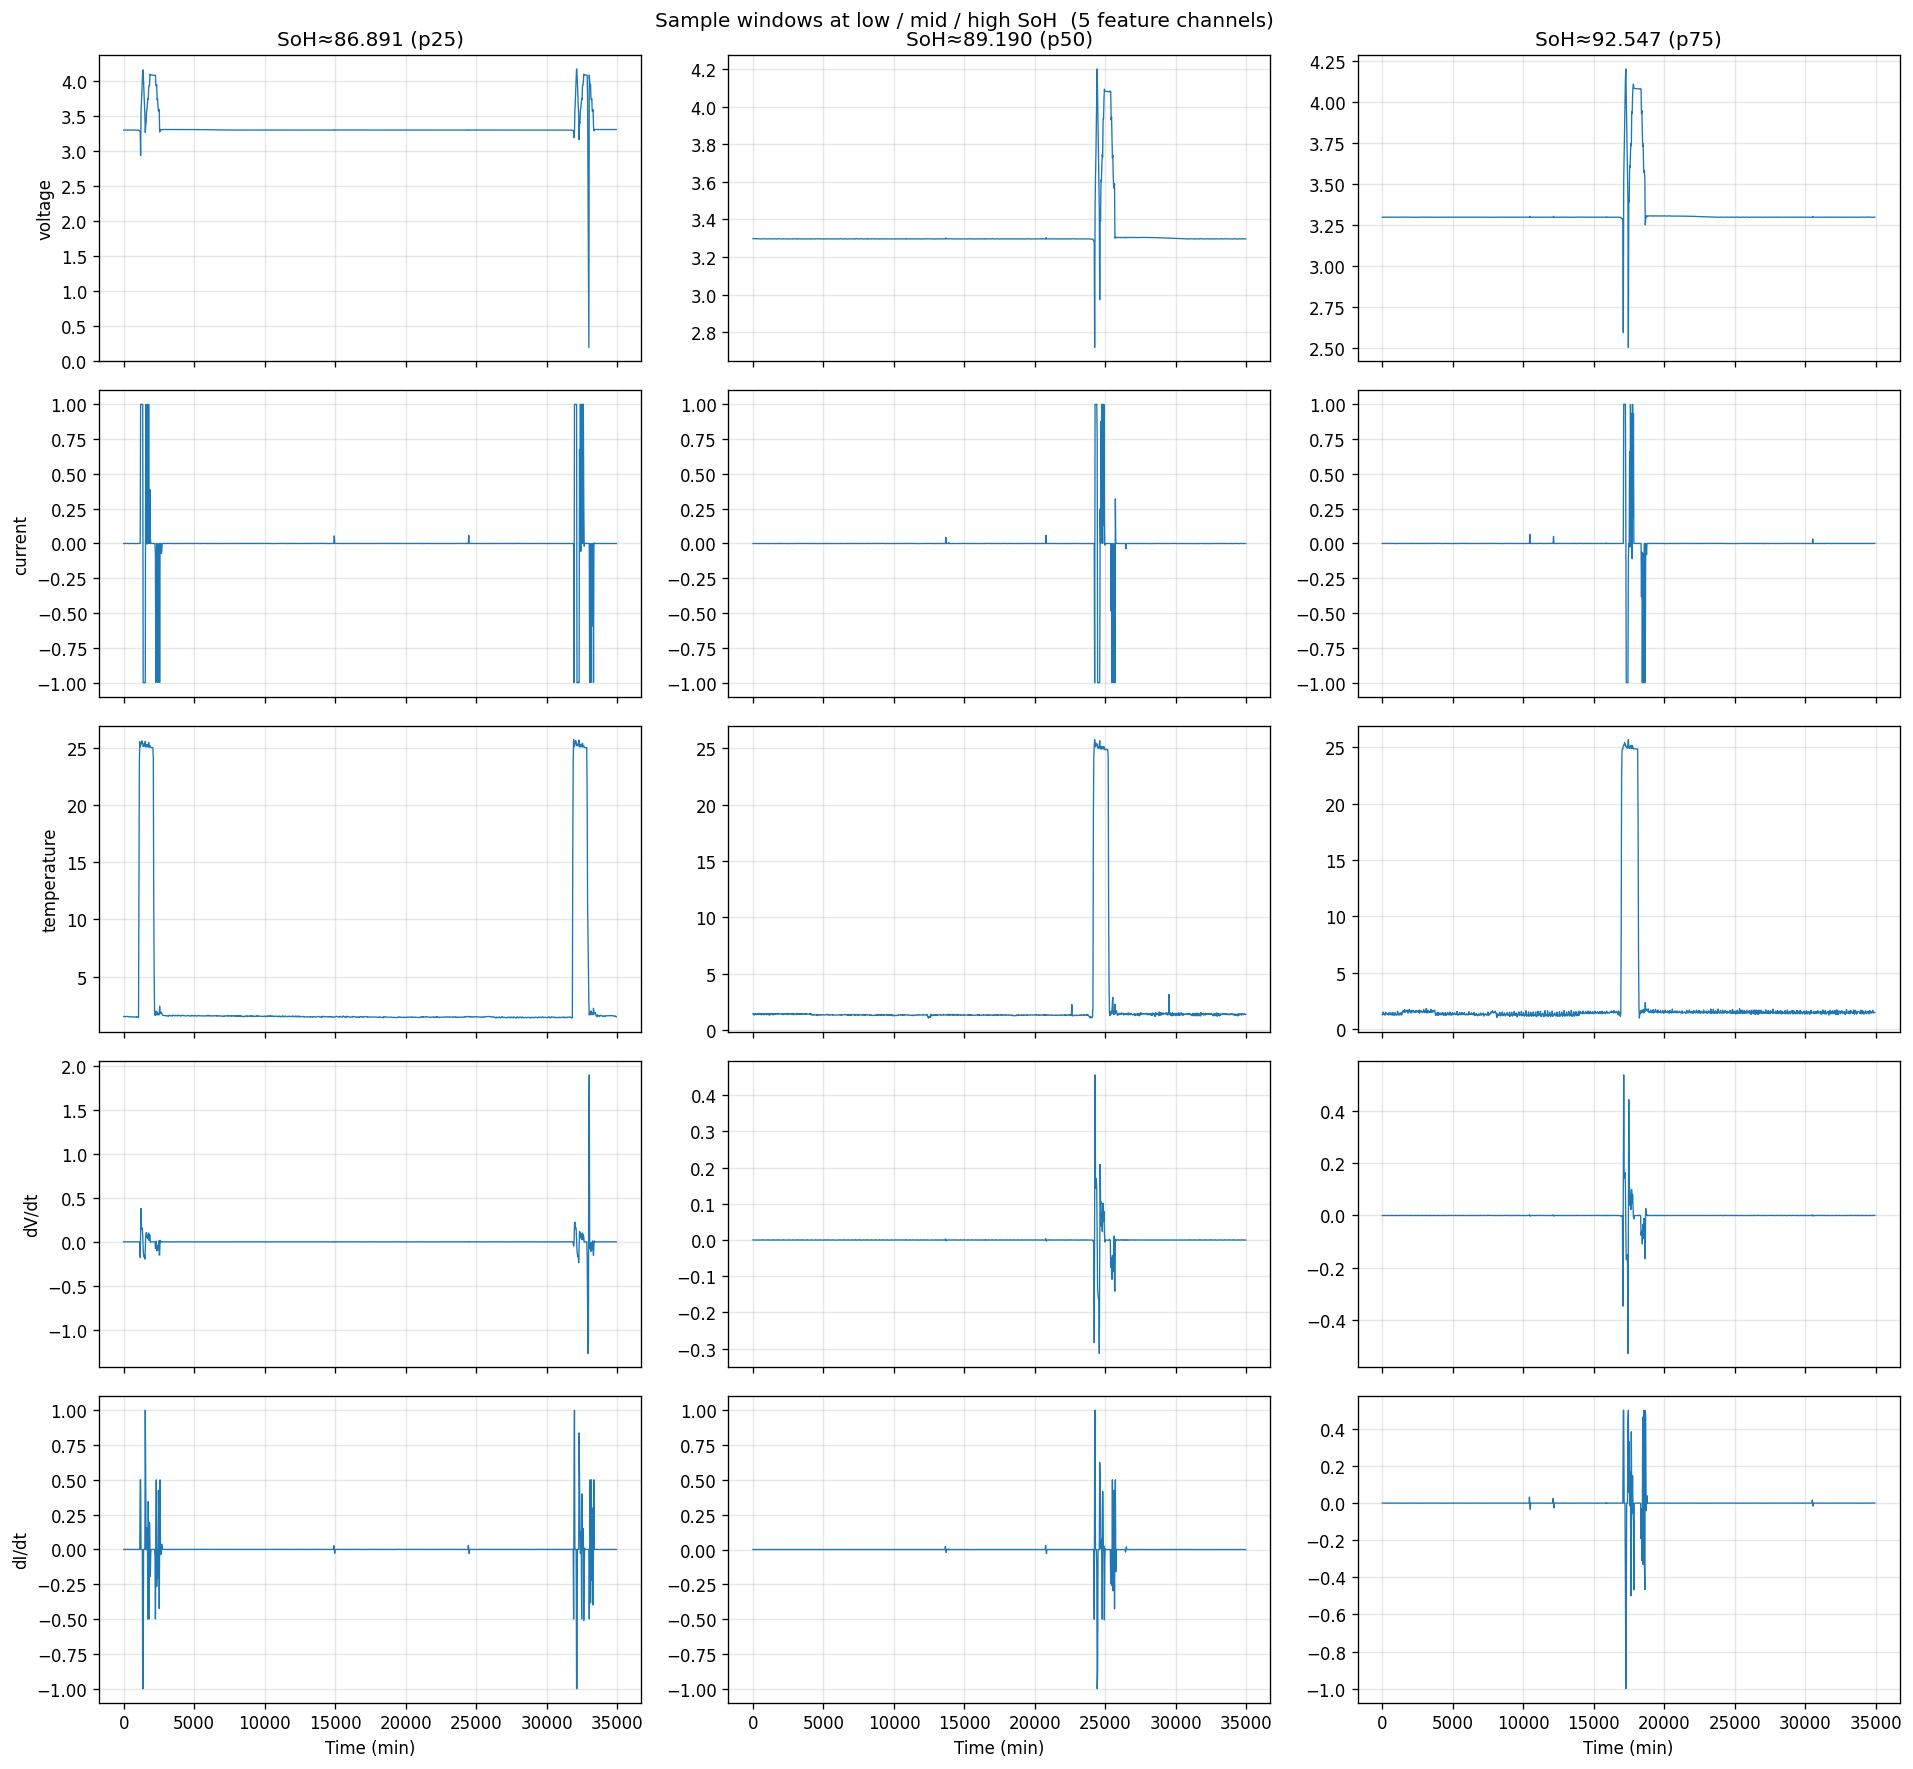

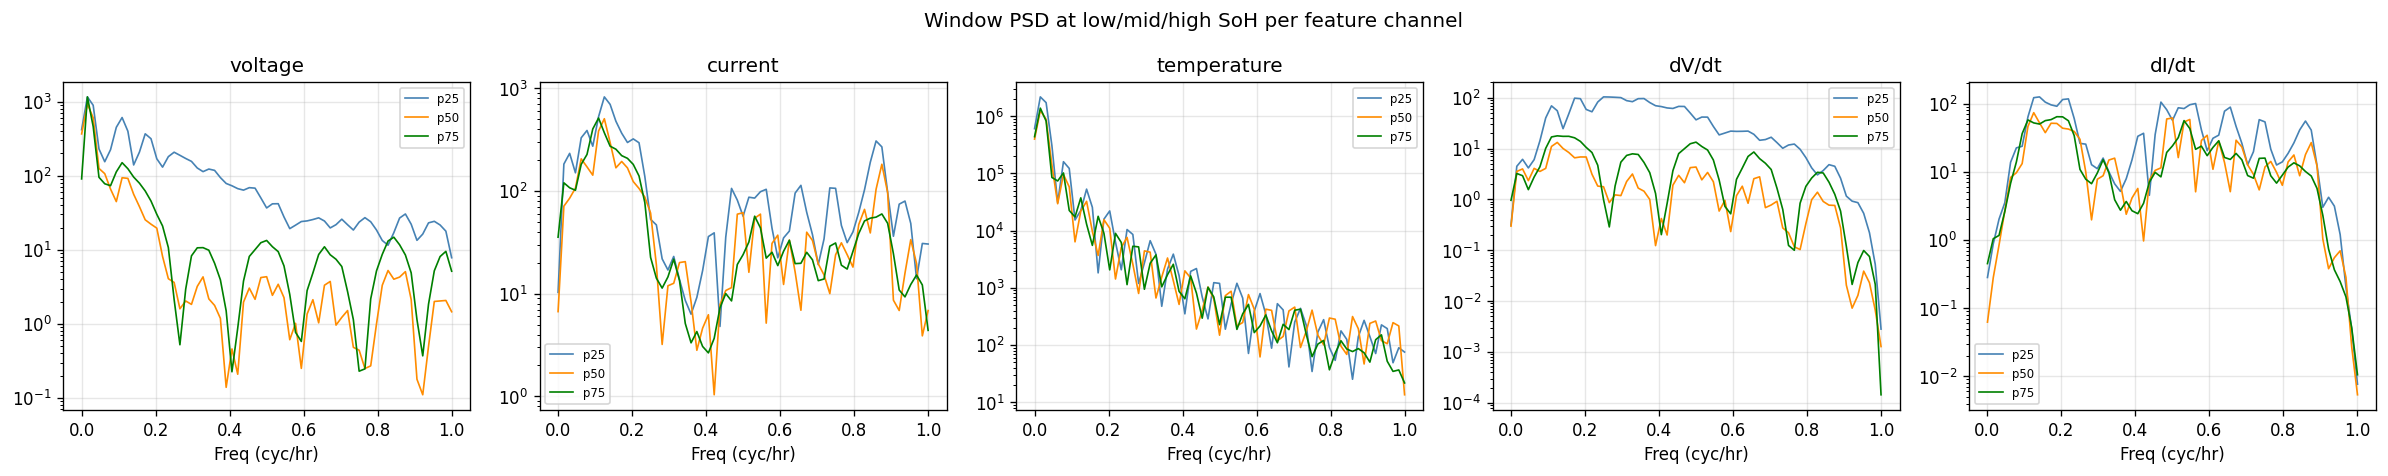

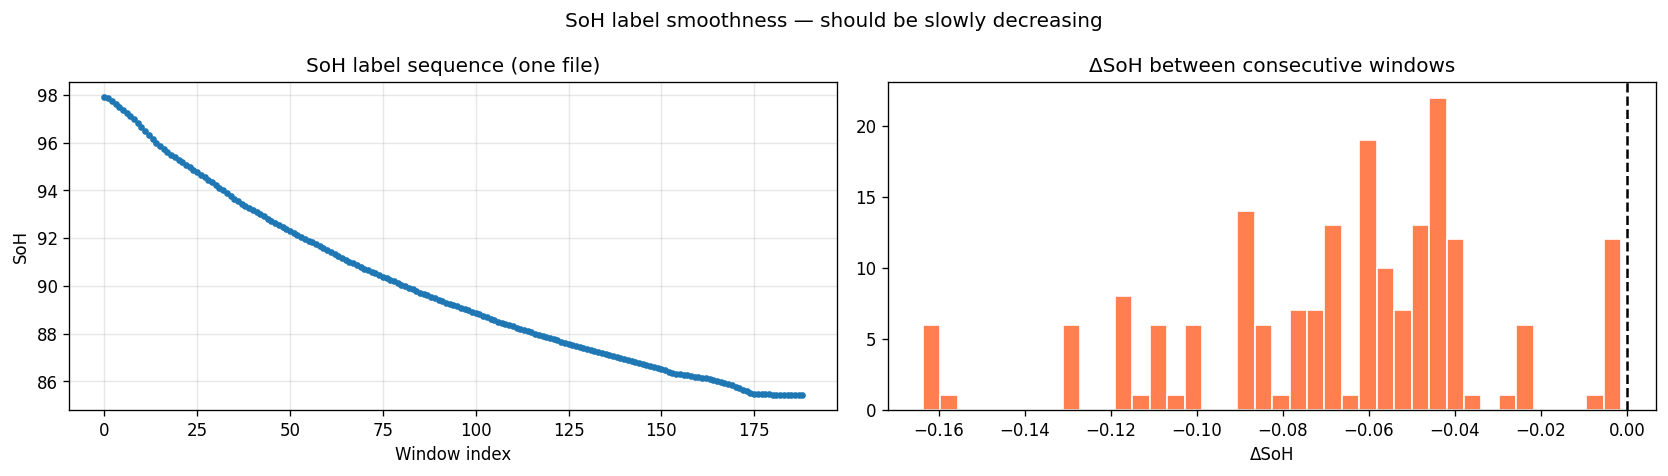

In [ ]:
wind_files_x = sorted([f for f in os.listdir(WIND_DIR) if f.startswith("X_")])
all_y_wind = []
windows_per_file = []
for f in wind_files_x:
    y = np.load(os.path.join(WIND_DIR, f.replace("X_", "y_")))
    all_y_wind.append(y)
    windows_per_file.append(len(y))
all_y_wind = np.concatenate(all_y_wind)
print(
    f"Total windows: {len(all_y_wind):,}  SoH: [{all_y_wind.min():.3f},{all_y_wind.max():.3f}]"
)

# 3.1 Windows per file
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(windows_per_file, bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(
    np.mean(windows_per_file),
    color="red",
    ls="--",
    label=f"mean={np.mean(windows_per_file):.0f}",
)
axes[0].set_title("Windows per source file")
axes[0].set_xlabel("# windows")
axes[0].legend()
axes[1].bar(range(len(windows_per_file)), sorted(windows_per_file), color="steelblue")
axes[1].set_title("Windows per file (sorted)")
axes[1].set_xlabel("File rank")
savefig("3_1_windows_per_file.png")

# 3.2 SoH label distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(all_y_wind, bins=80, color="steelblue", edgecolor="none")
axes[0].set_title("SoH distribution (all windows)")
axes[0].set_xlabel("SoH")
axes[1].boxplot(all_y_wind)
axes[1].set_title("SoH box plot")
axes[1].set_ylabel("SoH")
stats.probplot(all_y_wind, plot=axes[2])
axes[2].set_title("Q-Q plot")
fig.suptitle(
    f"n={len(all_y_wind):,}  mean={all_y_wind.mean():.3f}  std={all_y_wind.std():.3f}"
)
savefig("3_2_soh_label_distribution.png")

# 3.3 Sample windows at 3 SoH levels
Xw = np.load(os.path.join(WIND_DIR, wind_files_x[0]))
yw = np.load(os.path.join(WIND_DIR, wind_files_x[0].replace("X_", "y_")))
W = Xw.shape[1]
t_w = np.arange(W) * MINS_PER_SAMPLE
n_feat_w = Xw.shape[2]
# FEAT_COLS labels (5 features)
feat_names_w = (FEAT_COLS + [f"feat{i}" for i in range(len(FEAT_COLS), n_feat_w)])[
    :n_feat_w
]
pcts = [25, 50, 75]
chosen = [np.argmin(np.abs(yw - np.percentile(yw, p))) for p in pcts]
fig, axes = plt.subplots(n_feat_w, 3, figsize=(16, 3 * n_feat_w), sharex=True)
for col, (wi, pct) in enumerate(zip(chosen, pcts)):
    for row in range(n_feat_w):
        ax = axes[row][col]
        ax.plot(t_w, Xw[wi, :, row], lw=0.8)
        if row == 0:
            ax.set_title(f"SoH≈{yw[wi]:.3f} (p{pct})")
        if col == 0:
            ax.set_ylabel(feat_names_w[row])
        if row == n_feat_w - 1:
            ax.set_xlabel("Time (min)")
        ax.grid(alpha=0.3)
fig.suptitle("Sample windows at low / mid / high SoH  (5 feature channels)")
savefig("3_3_sample_windows.png")

# 3.4 Window PSD comparison at 3 SoH levels
fig, axes = plt.subplots(1, n_feat_w, figsize=(4 * n_feat_w, 4))
colors3 = ["steelblue", "darkorange", "green"]
for row, ax in enumerate(axes):
    for wi, pct, c in zip(chosen, pcts, colors3):
        s = Xw[wi, :, row]
        f_p, pxx = signal.welch(s, fs=FS, nperseg=min(128, W // 2))
        ax.semilogy(f_p * 3600, pxx, color=c, lw=1, label=f"p{pct}")
    ax.set_title(feat_names_w[row])
    ax.set_xlabel("Freq (cyc/hr)")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
fig.suptitle("Window PSD at low/mid/high SoH per feature channel")
savefig("3_4_window_psd_soh.png")

# 3.5 Label smoothness check
yw0 = np.load(os.path.join(WIND_DIR, wind_files_x[0].replace("X_", "y_")))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(yw0, lw=0.8, marker="o", ms=3)
axes[0].set_title("SoH label sequence (one file)")
axes[0].set_xlabel("Window index")
axes[0].set_ylabel("SoH")
axes[0].grid(alpha=0.3)
diff = np.diff(yw0)
axes[1].hist(diff, bins=40, color="coral", edgecolor="white")
axes[1].axvline(0, color="black", ls="--")
axes[1].set_title("ΔSoH between consecutive windows")
axes[1].set_xlabel("ΔSoH")
fig.suptitle("SoH label smoothness — should be slowly decreasing")
savefig("3_5_label_smoothness.png")



# Section 4 — Normalized Dataset (GRU/XGB)

GRU train:(7925, 1166, 5)  val:(2538, 1166, 5)  test:(2220, 1166, 5)


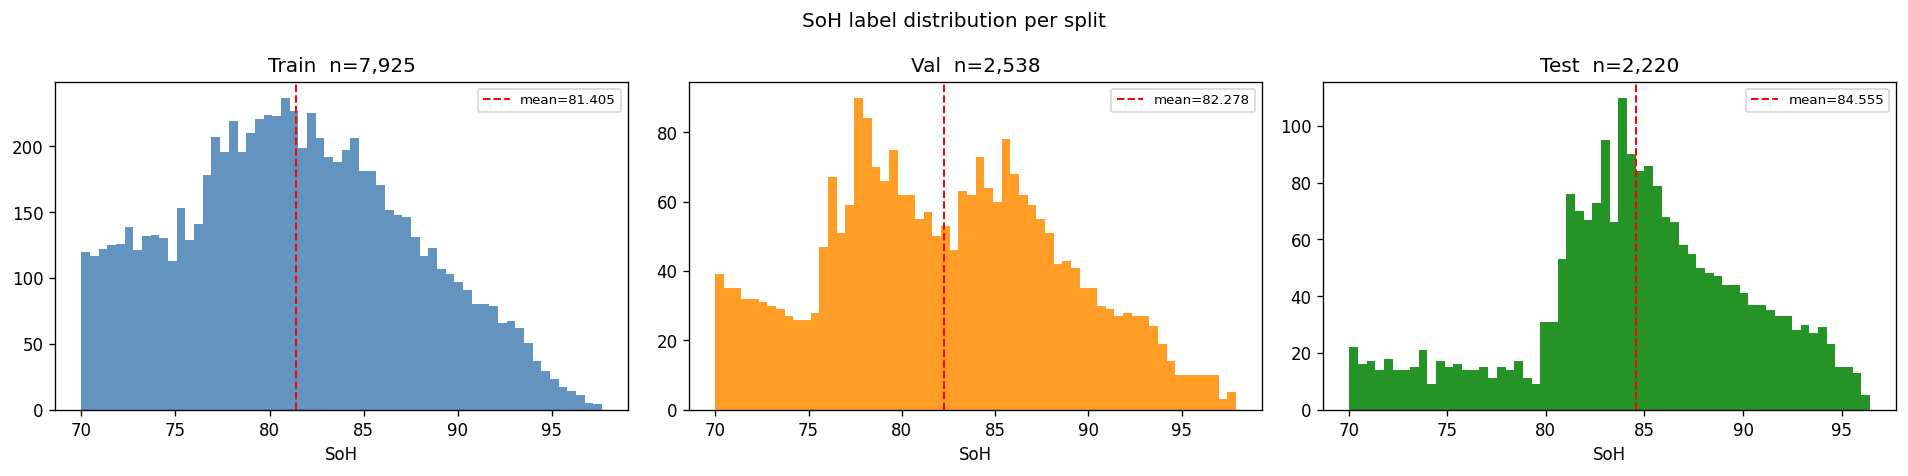

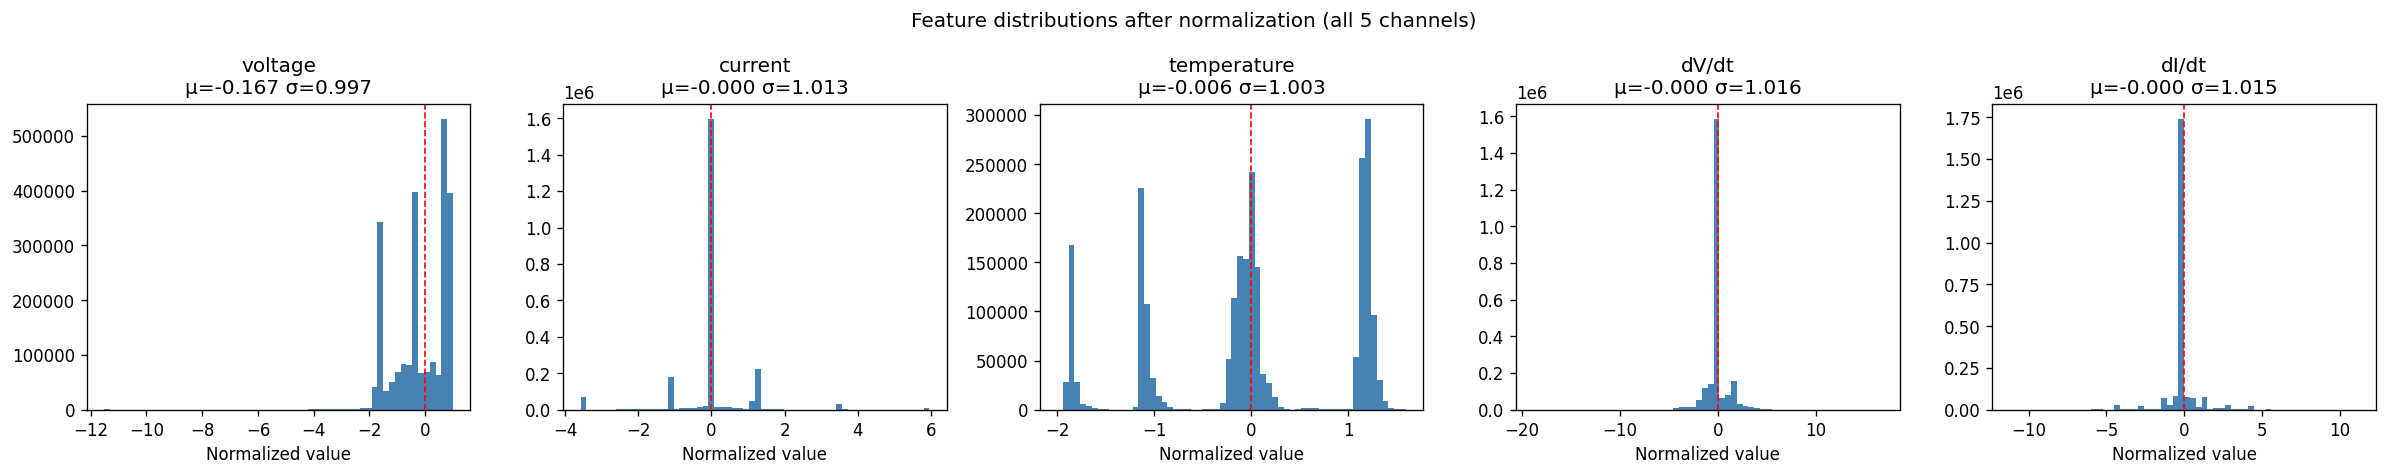

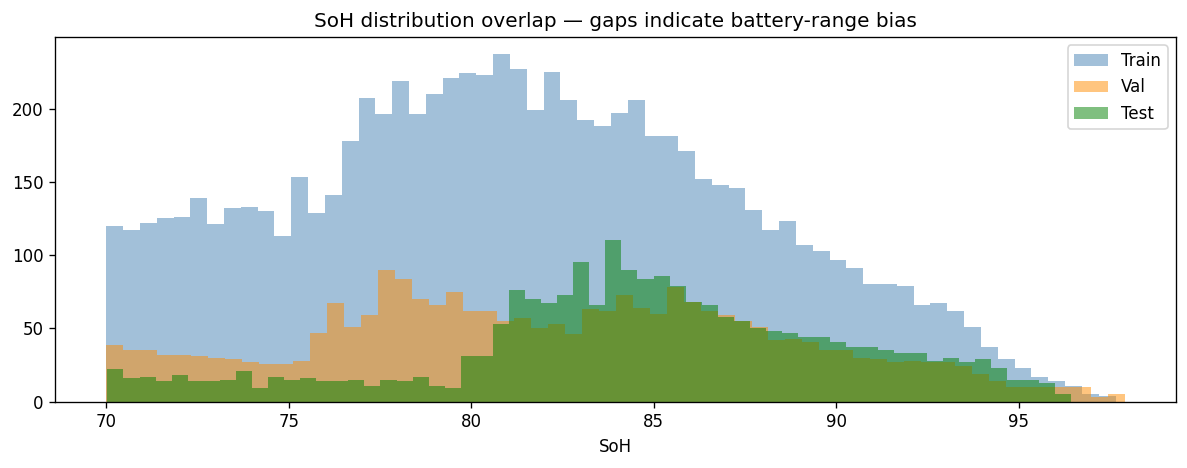

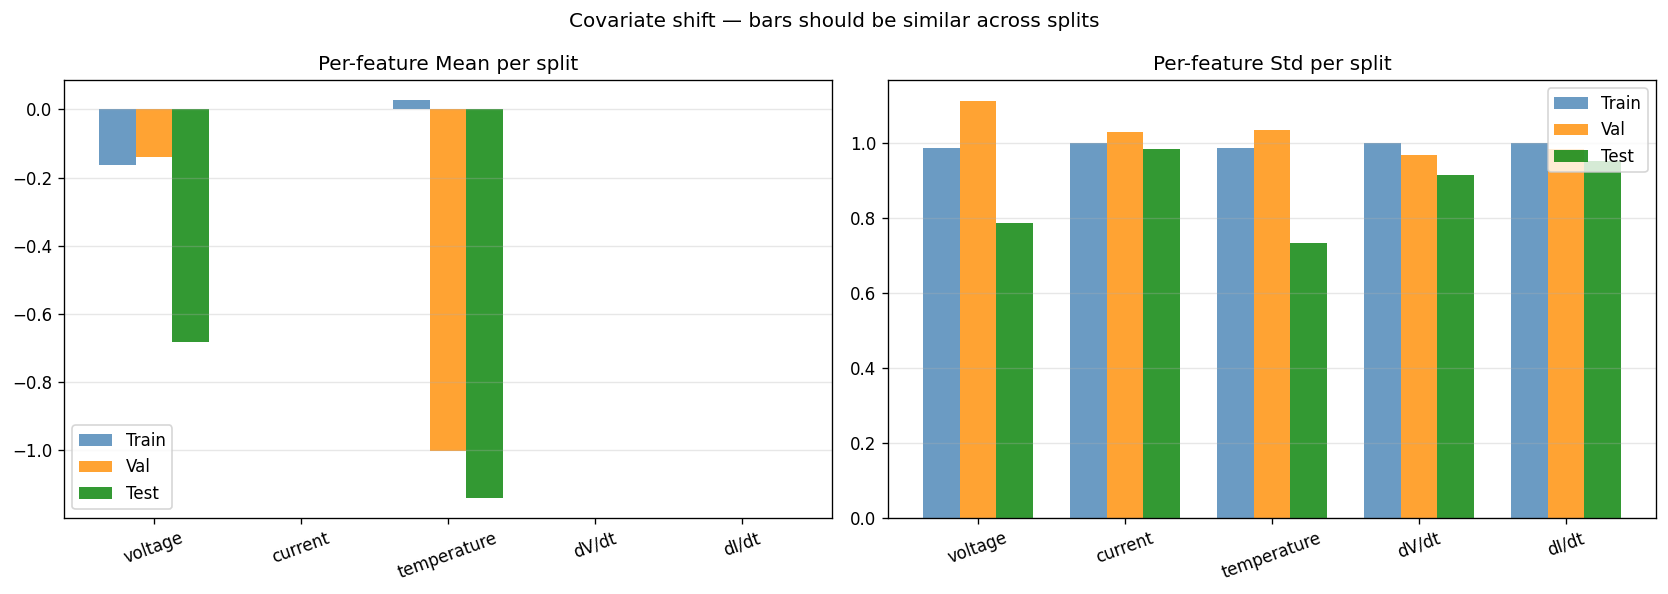

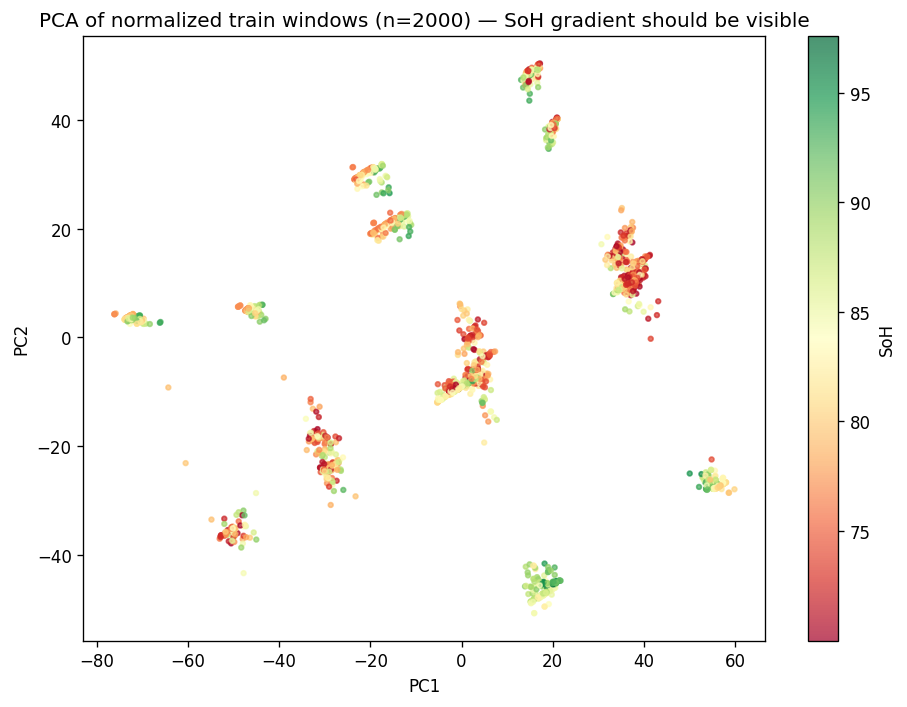

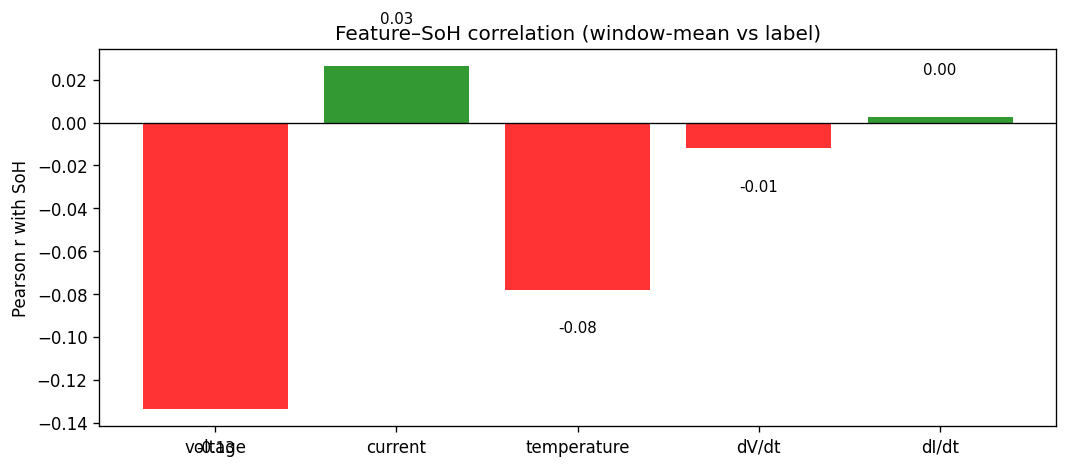

In [ ]:
X_train = np.load(os.path.join(NORM_DIR, "X_train.npy"))
y_train = np.load(os.path.join(NORM_DIR, "y_train.npy"))
X_val = np.load(os.path.join(NORM_DIR, "X_val.npy"))
y_val = np.load(os.path.join(NORM_DIR, "y_val.npy"))
X_test = np.load(os.path.join(NORM_DIR, "X_test.npy"))
y_test = np.load(os.path.join(NORM_DIR, "y_test.npy"))
print(f"GRU train:{X_train.shape}  val:{X_val.shape}  test:{X_test.shape}")

n_feat = X_train.shape[2]
feat_labels = (FEAT_COLS + [f"feat{i}" for i in range(len(FEAT_COLS), n_feat)])[:n_feat]

# 4.1 Label distribution per split
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, y, name, c in zip(
    axes,
    [y_train, y_val, y_test],
    ["Train", "Val", "Test"],
    ["steelblue", "darkorange", "green"],
):
    ax.hist(y, bins=60, color=c, alpha=0.85, edgecolor="none")
    ax.axvline(y.mean(), color="red", ls="--", lw=1.2, label=f"mean={y.mean():.3f}")
    ax.set_title(f"{name}  n={len(y):,}")
    ax.set_xlabel("SoH")
    ax.legend(fontsize=8)
fig.suptitle("SoH label distribution per split")
savefig("4_1_label_dist.png")

# 4.2 Feature distributions after normalization (all 5 channels)
idx = np.random.choice(X_train.shape[0], min(2000, X_train.shape[0]), replace=False)
Xs = X_train[idx].reshape(-1, n_feat)
fig, axes = plt.subplots(1, n_feat, figsize=(4 * n_feat, 4))
for ax, i in zip(axes, range(n_feat)):
    ax.hist(Xs[:, i], bins=60, color="steelblue", edgecolor="none")
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_title(f"{feat_labels[i]}\nμ={Xs[:, i].mean():.3f} σ={Xs[:, i].std():.3f}")
    ax.set_xlabel("Normalized value")
fig.suptitle("Feature distributions after normalization (all 5 channels)")
savefig("4_2_feature_dist.png")

# 4.3 Split overlap
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(y_train, bins=60, alpha=0.5, label="Train", color="steelblue")
ax.hist(y_val, bins=60, alpha=0.5, label="Val", color="darkorange")
ax.hist(y_test, bins=60, alpha=0.5, label="Test", color="green")
ax.set_xlabel("SoH")
ax.legend()
ax.set_title("SoH distribution overlap — gaps indicate battery-range bias")
savefig("4_3_split_overlap.png")

# 4.4 Covariate shift
splits = {"Train": X_train, "Val": X_val, "Test": X_test}
means = {k: v.mean(axis=(0, 1)) for k, v in splits.items()}
stds = {k: v.std(axis=(0, 1)) for k, v in splits.items()}
x_pos = np.arange(n_feat)
width = 0.25
colors_s = ["steelblue", "darkorange", "green"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, stat, title in zip(axes, [means, stds], ["Mean", "Std"]):
    for i, (sname, vals) in enumerate(stat.items()):
        ax.bar(
            x_pos + i * width, vals, width, label=sname, color=colors_s[i], alpha=0.8
        )
    ax.set_xticks(x_pos + width)
    ax.set_xticklabels(feat_labels, rotation=20)
    ax.set_title(f"Per-feature {title} per split")
    ax.legend()
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Covariate shift — bars should be similar across splits")
savefig("4_4_covariate_shift.png")

# 4.5 PCA
from numpy.linalg import svd as _svd

N_PCA = min(2000, X_train.shape[0])
idx_p = np.random.choice(X_train.shape[0], N_PCA, replace=False)
Xf = X_train[idx_p].reshape(N_PCA, -1)
yf = y_train[idx_p]
Xc = Xf - Xf.mean(axis=0)
U, S, _ = _svd(Xc, full_matrices=False)
Z = U[:, :2] * S[:2]
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=yf, cmap="RdYlGn", s=8, alpha=0.7)
plt.colorbar(sc, ax=ax, label="SoH")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(
    f"PCA of normalized train windows (n={N_PCA}) — SoH gradient should be visible"
)
savefig("4_5_pca.png")

# 4.6 Feature-SoH correlation
feat_means = X_train.mean(axis=1)
corrs = np.array([np.corrcoef(feat_means[:, i], y_train)[0, 1] for i in range(n_feat)])
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(
    feat_labels, corrs, color=["green" if c > 0 else "red" for c in corrs], alpha=0.8
)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Pearson r with SoH")
ax.set_title("Feature–SoH correlation (window-mean vs label)")
for i, c in enumerate(corrs):
    ax.text(i, c + 0.02 * (1 if c >= 0 else -1), f"{c:.2f}", ha="center", fontsize=9)
savefig("4_6_feature_soh_corr.png")



# Section 5 — CNN Dataset

CNN train:(7922, 1166, 5)  val:(2538, 1166, 5)  test:(2220, 1166, 5)


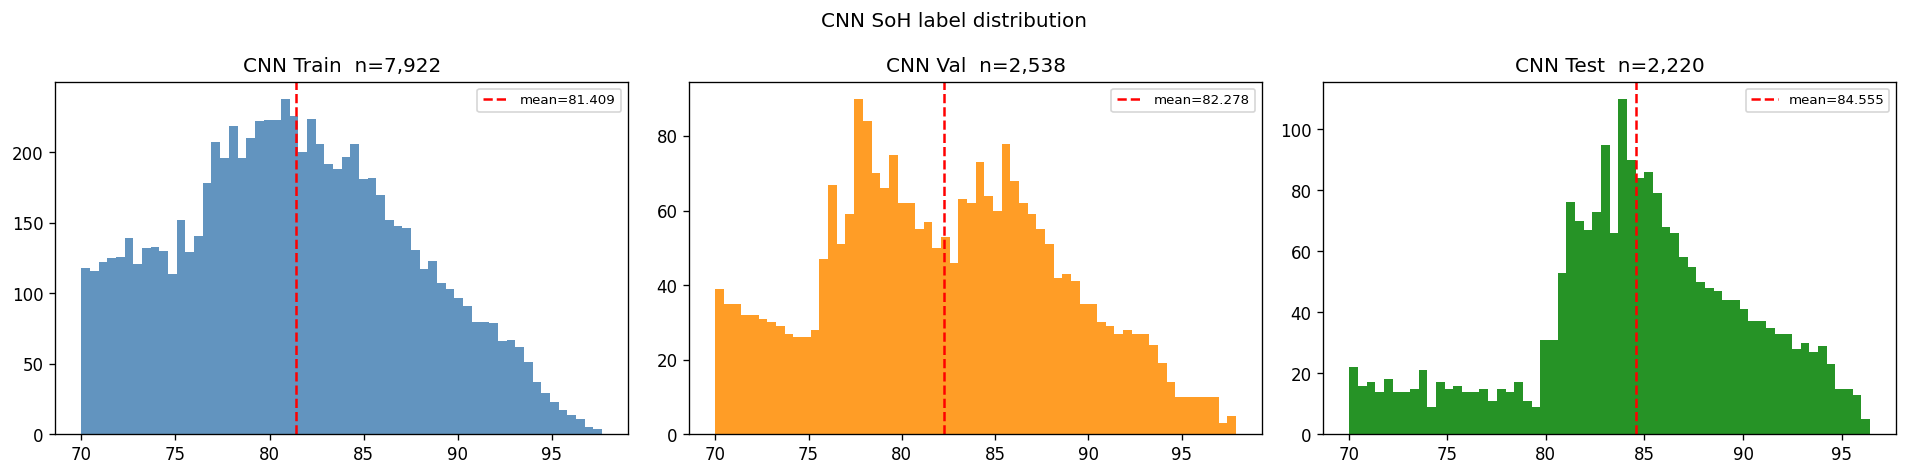

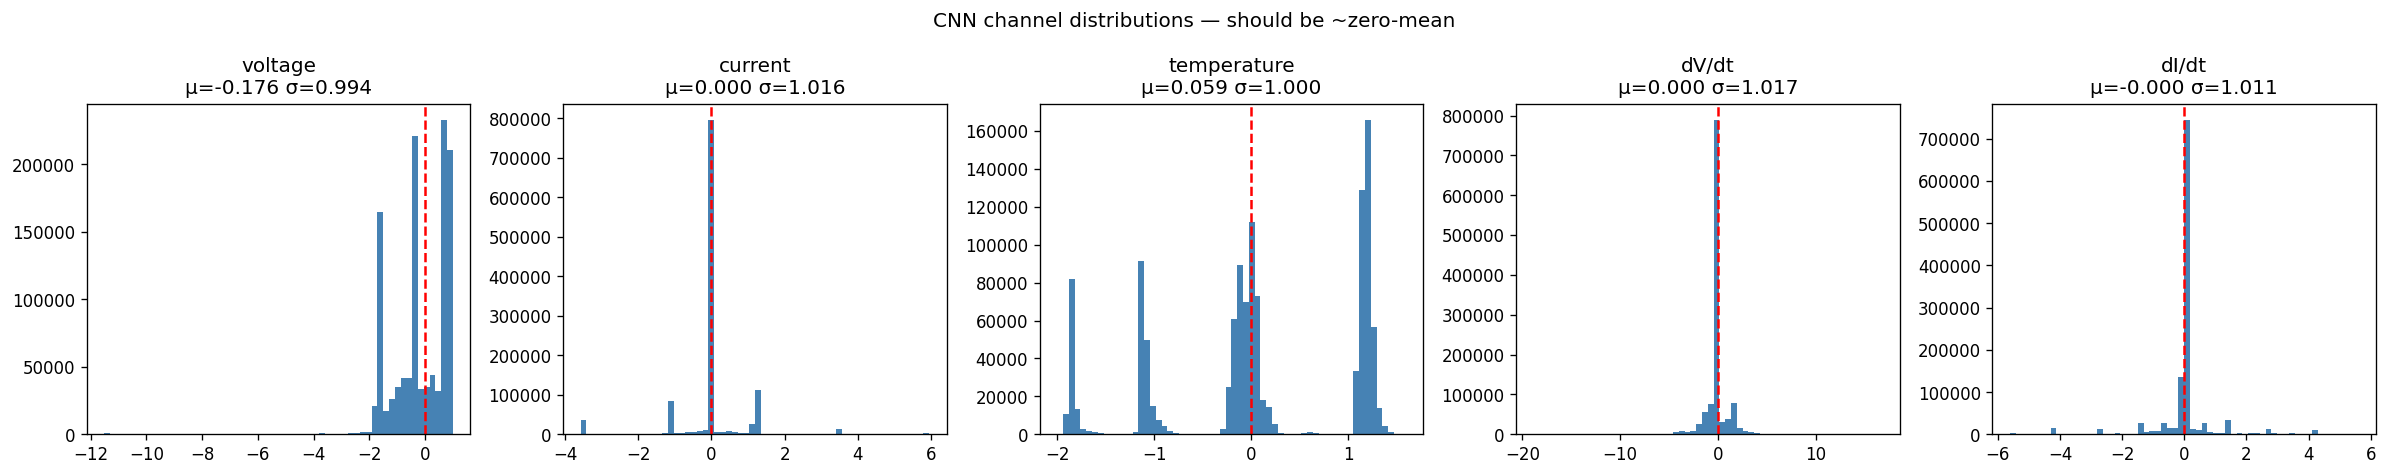

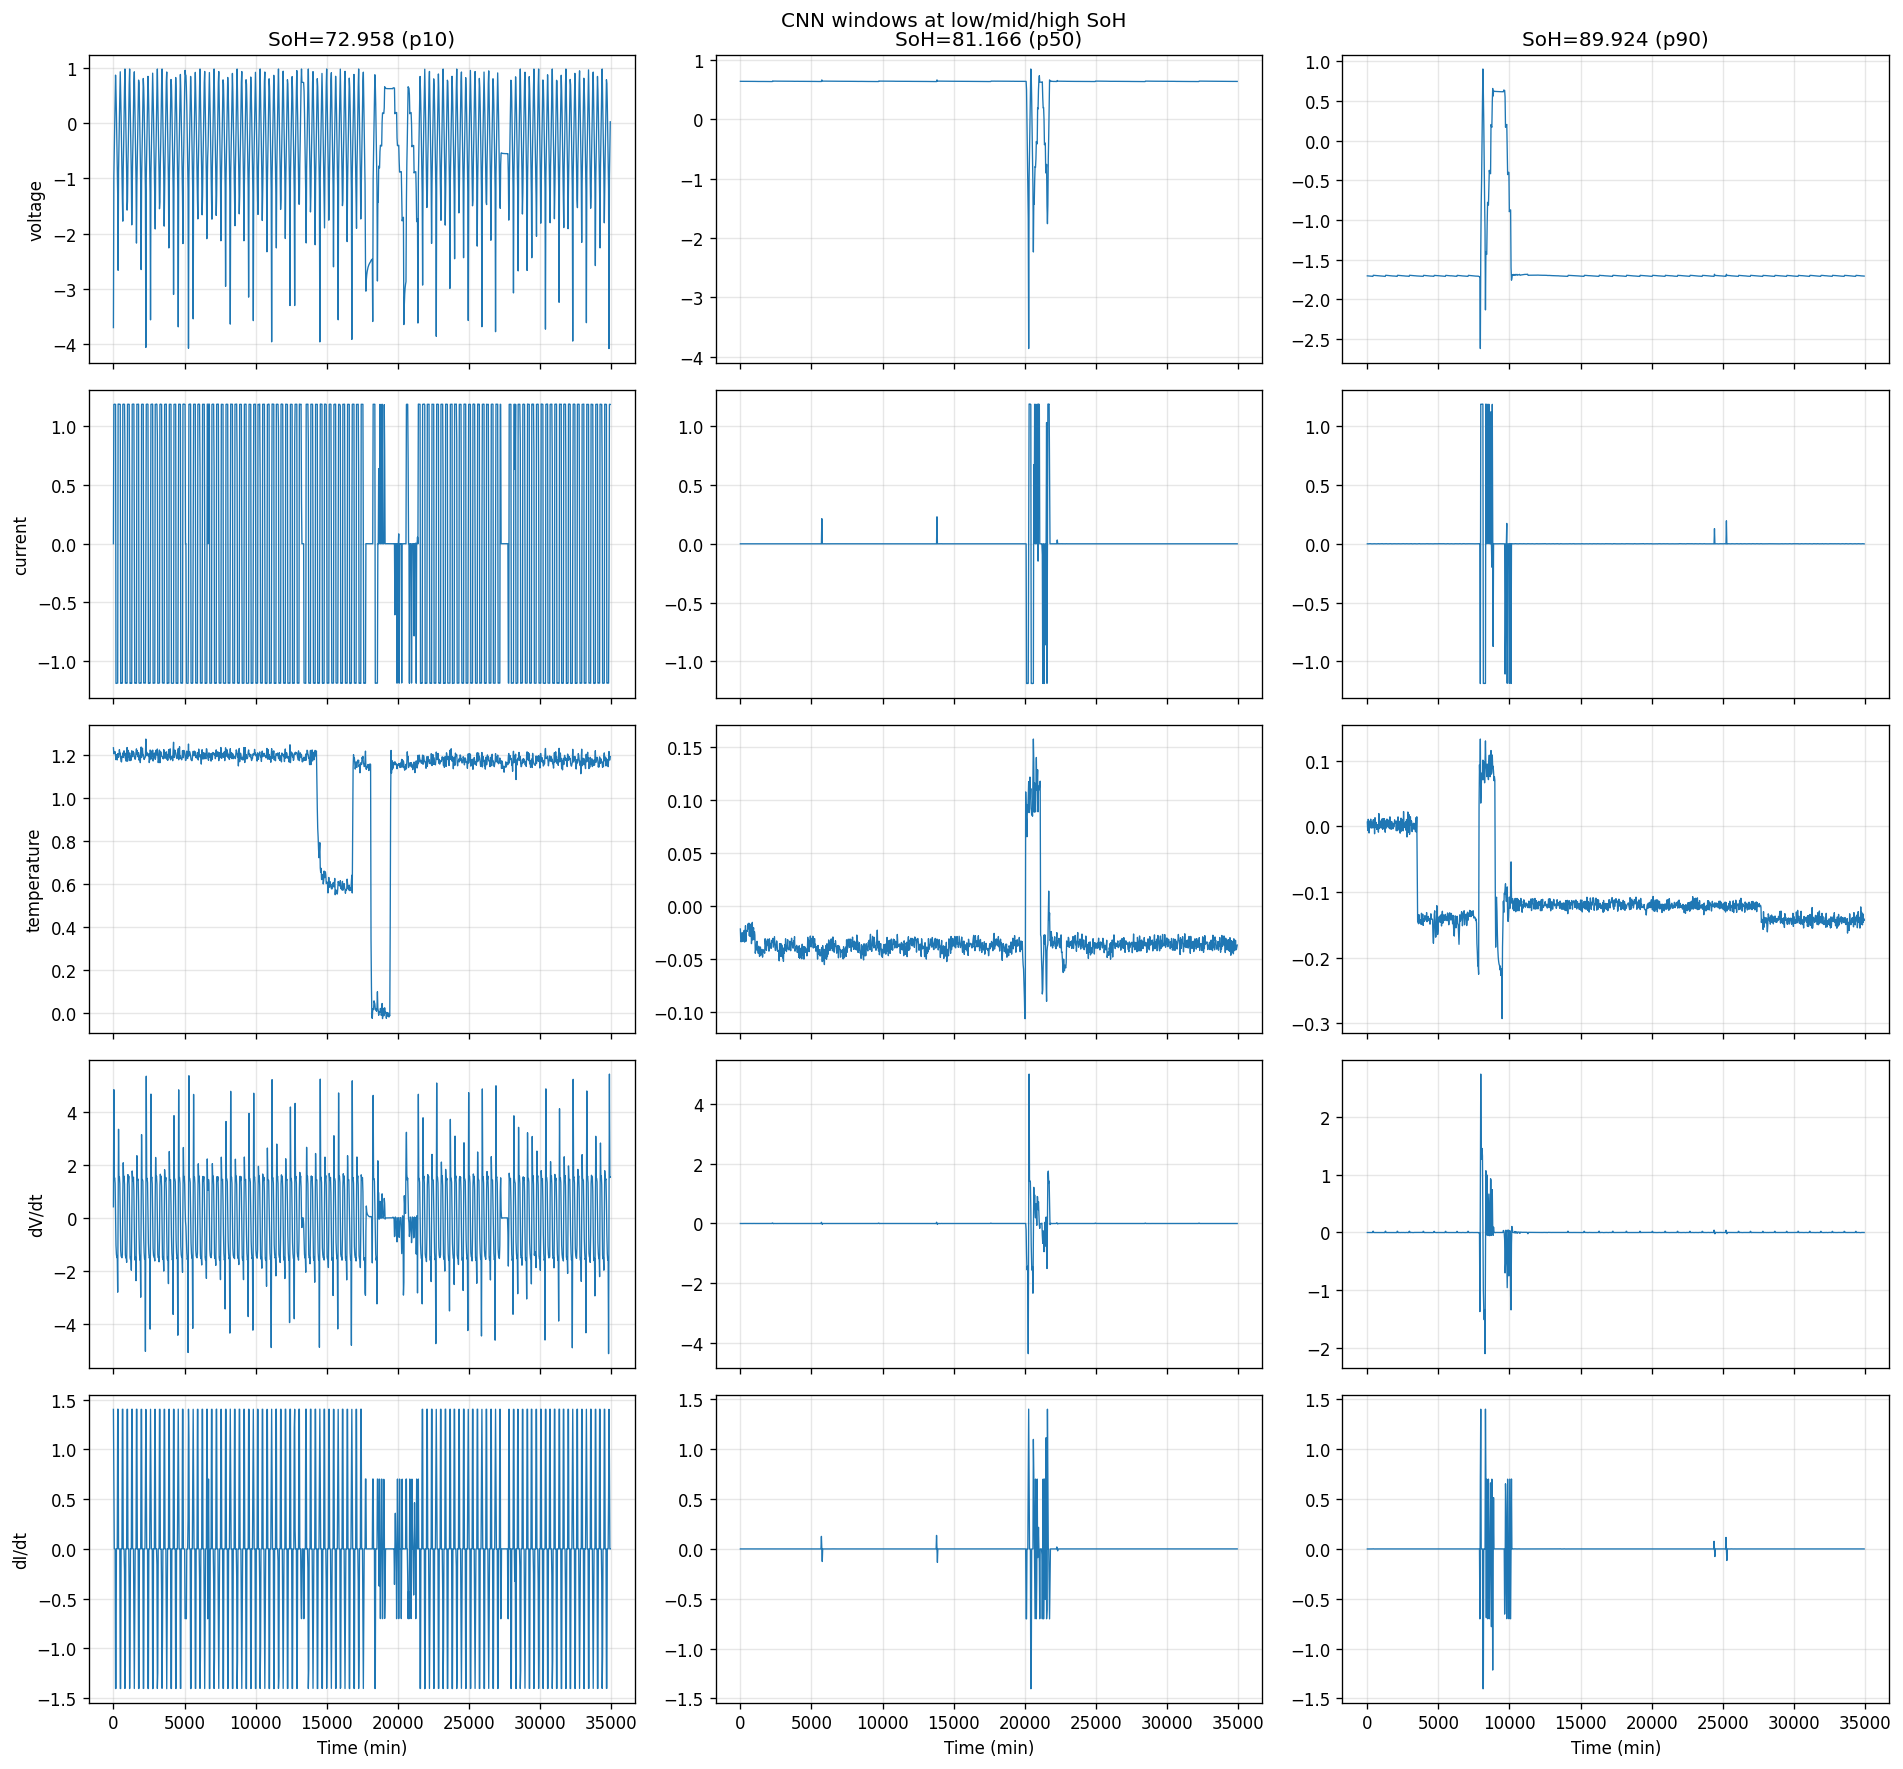

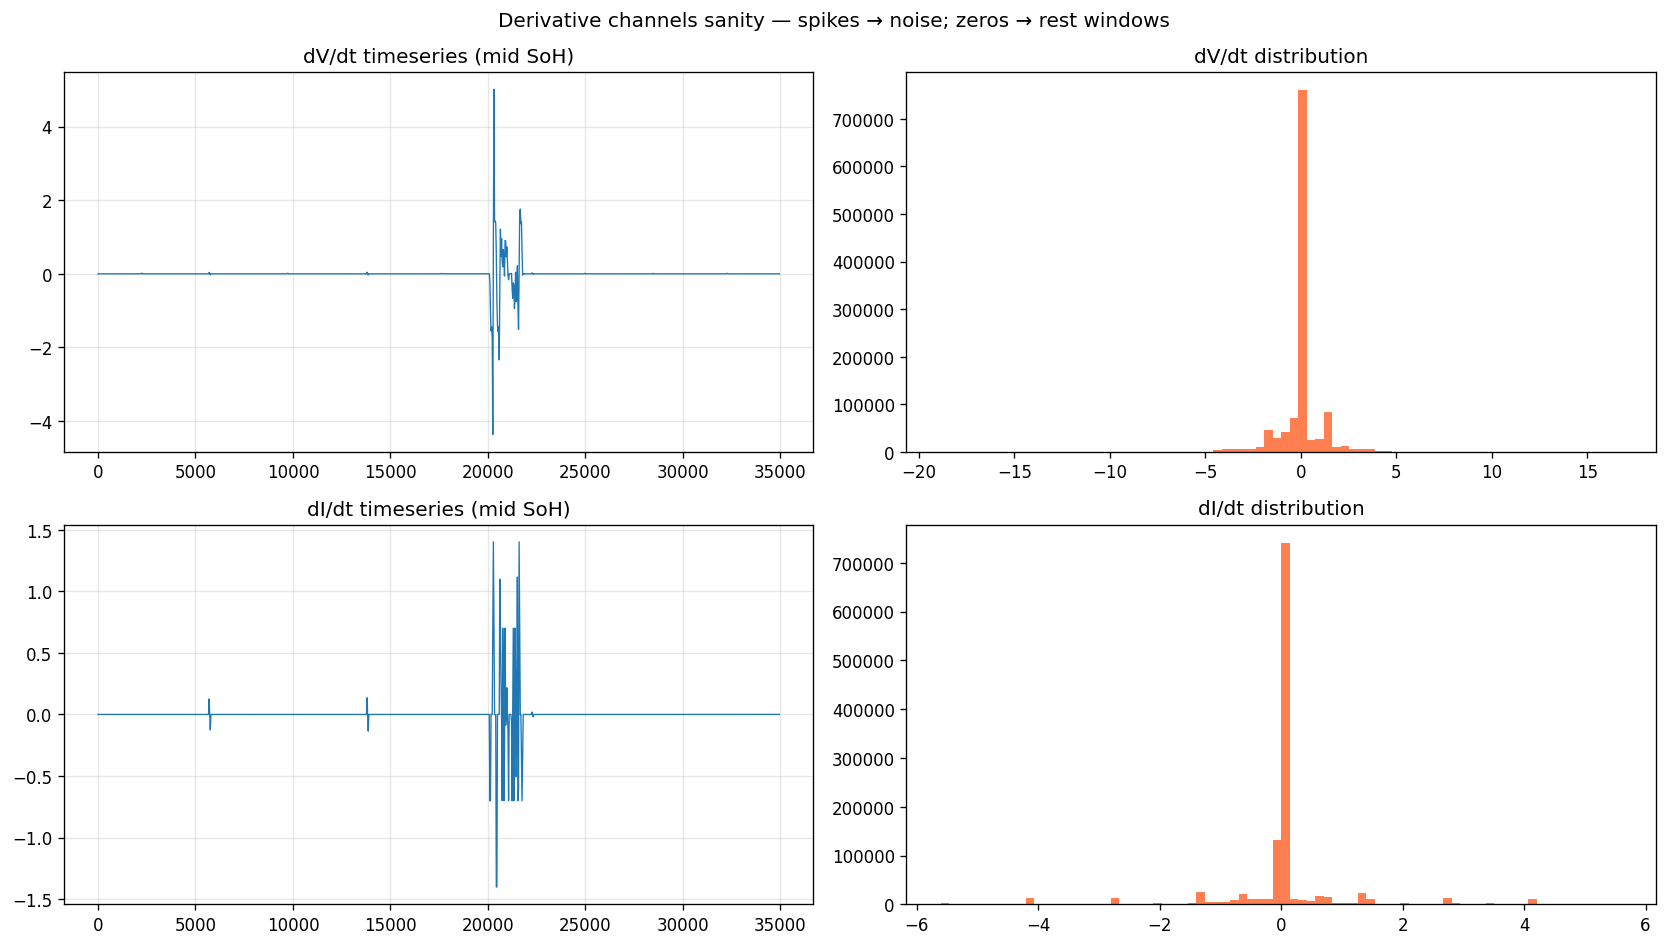

In [ ]:
Xc_train = np.load(os.path.join(CNN_NORM_DIR, "X_train.npy"))
yc_train = np.load(os.path.join(CNN_NORM_DIR, "y_train.npy"))
Xc_val = np.load(os.path.join(CNN_NORM_DIR, "X_val.npy"))
yc_val = np.load(os.path.join(CNN_NORM_DIR, "y_val.npy"))
Xc_test = np.load(os.path.join(CNN_NORM_DIR, "X_test.npy"))
yc_test = np.load(os.path.join(CNN_NORM_DIR, "y_test.npy"))
print(f"CNN train:{Xc_train.shape}  val:{Xc_val.shape}  test:{Xc_test.shape}")
Wc = Xc_train.shape[1]
nc = Xc_train.shape[2]
t_cnn = np.arange(Wc) * MINS_PER_SAMPLE

# 5.1 Label distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, y, name, c in zip(
    axes,
    [yc_train, yc_val, yc_test],
    ["Train", "Val", "Test"],
    ["steelblue", "darkorange", "green"],
):
    ax.hist(y, bins=60, color=c, alpha=0.85, edgecolor="none")
    ax.axvline(y.mean(), color="red", ls="--", label=f"mean={y.mean():.3f}")
    ax.set_title(f"CNN {name}  n={len(y):,}")
    ax.legend(fontsize=8)
fig.suptitle("CNN SoH label distribution")
savefig("5_1_cnn_label_dist.png")

# 5.2 Channel distributions
idx_c = np.random.choice(Xc_train.shape[0], min(1000, Xc_train.shape[0]), replace=False)
Xcs = Xc_train[idx_c].reshape(-1, nc)
fig, axes = plt.subplots(1, nc, figsize=(4 * nc, 4))
for ax, i in zip(axes, range(nc)):
    ax.hist(Xcs[:, i], bins=60, color="steelblue", edgecolor="none")
    lbl = COL_NAMES_CNN[i] if i < len(COL_NAMES_CNN) else f"ch{i}"
    ax.set_title(f"{lbl}\nμ={Xcs[:, i].mean():.3f} σ={Xcs[:, i].std():.3f}")
    ax.axvline(0, color="red", ls="--")
fig.suptitle("CNN channel distributions — should be ~zero-mean")
savefig("5_2_cnn_chan_dist.png")

# 5.3 Sample windows at 3 SoH levels
pcts3 = [10, 50, 90]
chosen_c = [np.argmin(np.abs(yc_train - np.percentile(yc_train, p))) for p in pcts3]
fig, axes = plt.subplots(nc, 3, figsize=(16, 3 * nc), sharex=True)
if nc == 1:
    axes = axes[np.newaxis, :]
for col, (wi, pct) in enumerate(zip(chosen_c, pcts3)):
    for row in range(nc):
        ax = axes[row][col]
        ax.plot(t_cnn, Xc_train[wi, :, row], lw=0.8)
        if row == 0:
            ax.set_title(f"SoH={yc_train[wi]:.3f} (p{pct})")
        lbl = COL_NAMES_CNN[row] if row < len(COL_NAMES_CNN) else f"ch{row}"
        if col == 0:
            ax.set_ylabel(lbl)
        if row == nc - 1:
            ax.set_xlabel("Time (min)")
        ax.grid(alpha=0.3)
fig.suptitle("CNN windows at low/mid/high SoH")
savefig("5_3_cnn_sample_windows.png")

# 5.4 Derivative channels sanity (channels 3 & 4)
if nc >= 5:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for row, (ci, name) in enumerate(zip([3, 4], ["dV/dt", "dI/dt"])):
        axes[row][0].plot(t_cnn, Xc_train[chosen_c[1], :, ci], lw=0.8)
        axes[row][0].set_title(f"{name} timeseries (mid SoH)")
        axes[row][0].grid(alpha=0.3)
        vals = Xc_train[idx_c, :, ci].ravel()
        axes[row][1].hist(vals, bins=80, color="coral", edgecolor="none")
        axes[row][1].set_title(f"{name} distribution")
    fig.suptitle("Derivative channels sanity — spikes → noise; zeros → rest windows")
    savefig("5_4_derivatives_sanity.png")
